# Guía de Trabajo N° 11
## Clustering por densidad y probabilístico: DBSCAN y Modelos de Mezcla Gaussiana (GMM)
*Unidad 3: Métodos Ensemble y Aprendizaje No Supervisado*

| | |
|---|---|
| **Asignatura** | Machine Learning |
| **Unidad** | Unidad 3 — Métodos Ensemble y Aprendizaje No Supervisado |
| **Guía N°** | 11 — DBSCAN (desarrollo guiado) y GMM (reto) |
| **Tarea** | Clustering y detección de anomalías (aprendizaje no supervisado) |
| **Modalidad** | Parte A: desarrollo guiado con código · Parte B: reto sin código · Parte C: comparación |
| **Docente** | Pedro Andres Campos Poveda |
| **Estudiante** | Camila Alison Catorceno Orellana |
| **Fecha** | 20 de noviembre de 2026 |

**Contenido**

0. Preparación del entorno
1. Parte A — Modelo 1: DBSCAN (desarrollo guiado, Pasos 1 a 8 e indicadores)
2. Parte B — Modelo 2: Modelo de Mezcla Gaussiana (diseño propio del procedimiento e implementación)
3. Parte C — Comparación en dos escenarios, preguntas de análisis, experimentos adicionales y conclusión
4. Preguntas teóricas
5. Referencias

> **Regla de trabajo.** La etiqueta de referencia (`y_ref`: luna 0, luna 1 o atípico) nunca se usa para entrenar ni para tomar decisiones: eps, min_samples, K, tipo de covarianza, umbral de anomalías o número de fusiones se eligen solo con criterios internos. El ARI, el NMI y el conteo de atípicos reales aparecen después, como verificación didáctica.

## 0. Preparación del entorno

Se requiere Python 3 con scikit-learn (Pedregosa et al., 2011), scipy, numpy, pandas y matplotlib (`pip install -r requirements.txt`). Se fija `random_state=42` en la división de datos y en todos los modelos; la generación de atípicos usa la semilla 7 que indica la guía. La celda siguiente imprime las versiones con las que se obtuvieron los resultados comentados; la guía se calibró con scikit-learn 1.8 y con la 1.9.1 los valores de referencia de la Parte A se reproducen exactamente.

In [1]:
import sys
import sklearn, scipy, numpy, pandas, matplotlib
print('Python      :', sys.version.split()[0])
for lib in (sklearn, scipy, numpy, pandas, matplotlib):
    print(f'{lib.__name__:<12}:', lib.__version__)
pandas.set_option('display.width', 160)
pandas.set_option('display.max_columns', 20)

Python      : 3.13.18
sklearn     : 1.9.1
scipy       : 1.18.1
numpy       : 2.5.3
pandas      : 3.0.5
matplotlib  : 3.11.2


# Parte A — Modelo 1: DBSCAN (desarrollo guiado)

DBSCAN (Ester et al., 1996) define un cluster como una **región densa** de puntos. Con dos parámetros, `eps` (radio de vecindad) y `min_samples` (puntos mínimos dentro del radio, contando el propio punto en scikit-learn), clasifica cada punto como **núcleo** (tiene al menos `min_samples` vecinos a distancia ≤ eps), **frontera** (no es núcleo, pero está en el radio de un núcleo) o **ruido** (ninguna de las dos; etiqueta −1). Los núcleos conectados por cadenas de vecindad forman un cluster. Por eso encuentra grupos de forma arbitraria, no necesita fijar k y detecta anomalías de forma nativa. Sus debilidades: un solo eps no sirve para grupos de densidades muy distintas y pierde eficacia en alta dimensión (Géron, 2019; Schubert et al., 2017).

### Paso 1 — Importar librerías

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score)

### Paso 2 — Generar el dataset

Dataset **sintético controlado**: dos medias lunas entrelazadas con ruido gaussiano (`make_moons`) más 20 atípicos uniformes en el rectángulo [−1,5; 2,5] × [−1,0; 1,5].

In [3]:
X_m, y_m = make_moons(n_samples=600, noise=0.08, random_state=42)
rng = np.random.RandomState(7)
X_out = rng.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(20, 2))   # atípicos
X = np.vstack([X_m, X_out])
y_ref = np.concatenate([y_m, -np.ones(20, dtype=int)])   # SOLO validación externa
df = pd.DataFrame(X, columns=['x1', 'x2'])
print(df.shape)
print(pd.Series(y_ref).value_counts())
print('Nulos:', df.isna().sum().sum(), '| filas duplicadas:', df.duplicated().sum())

(620, 2)
 0    300
 1    300
-1     20
Name: count, dtype: int64
Nulos: 0 | filas duplicadas: 0


**Resultado.** Hay 620 puntos y 2 variables continuas, sin nulos ni duplicados: 300 por luna y 20 atípicos. La etiqueta queda en `y_ref` y no vuelve a usarse hasta la validación externa del Paso 8.

### Paso 3 — Análisis exploratorio de datos (EDA)

Un EDA orientado a métodos de densidad responde tres preguntas: qué **forma** tienen los grupos, si los atípicos se ven **variable por variable** o solo en el plano, y si la **escala** de las variables es comparable (eps es un radio).

           x1      x2
count  620.00  620.00
mean     0.50    0.26
std      0.88    0.51
min     -1.19   -0.94
25%     -0.09   -0.20
50%      0.50    0.26
75%      1.05    0.72
max      2.41    1.38
Nulos: 0


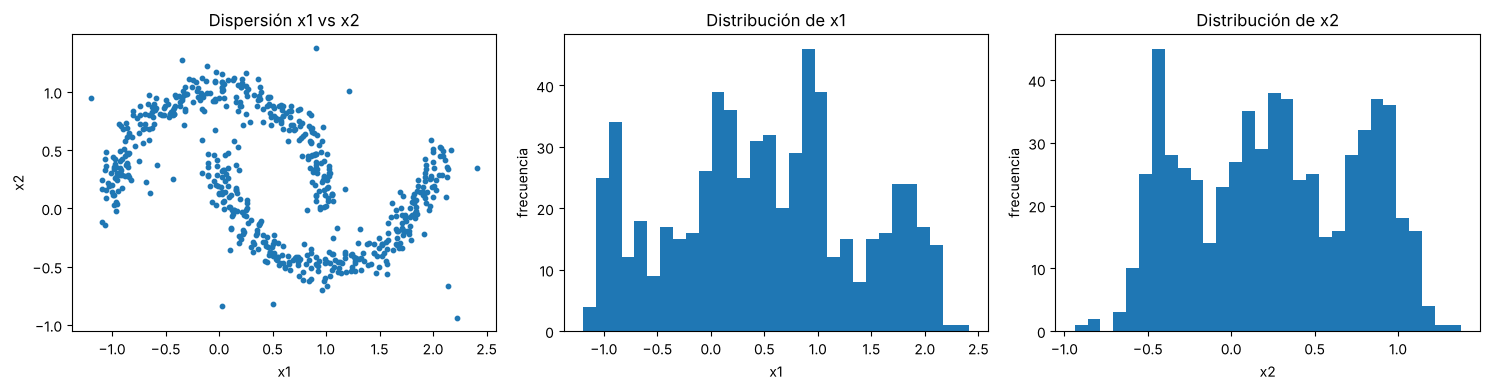

Atípicos IQR: {'x1': 0, 'x2': 0}
Correlación x1-x2: -0.433


In [4]:
print(df.describe().round(2))
print('Nulos:', df.isna().sum().sum())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(df.x1, df.x2, s=10); ax[0].set_title('Dispersión x1 vs x2')
ax[0].set_xlabel('x1'); ax[0].set_ylabel('x2')
ax[1].hist(df.x1, bins=30); ax[1].set_title('Distribución de x1'); ax[1].set_xlabel('x1'); ax[1].set_ylabel('frecuencia')
ax[2].hist(df.x2, bins=30); ax[2].set_title('Distribución de x2'); ax[2].set_xlabel('x2'); ax[2].set_ylabel('frecuencia')
plt.tight_layout(); plt.show()
# Atípicos univariados por IQR
Q1, Q3 = df.quantile(0.25), df.quantile(0.75); IQR = Q3 - Q1
print('Atípicos IQR:', ((df < Q1 - 1.5*IQR) | (df > Q3 + 1.5*IQR)).sum().to_dict())
print('Correlación x1-x2:', round(df.corr().iloc[0, 1], 3))

    mínimo  límite inf. IQR  máximo  límite sup. IQR
x1   -1.19            -1.80    2.41             2.77
x2   -0.94            -1.58    1.38             2.11

Desviación estándar: x1 = 0.88 | x2 = 0.51 | cociente = 1.72

Distancia al 5.º vecino -> percentiles 50 / 90 / 95 / 99: [0.064 0.104 0.135 0.328]
Puntos con distancia > 3 × mediana (0.191): 17


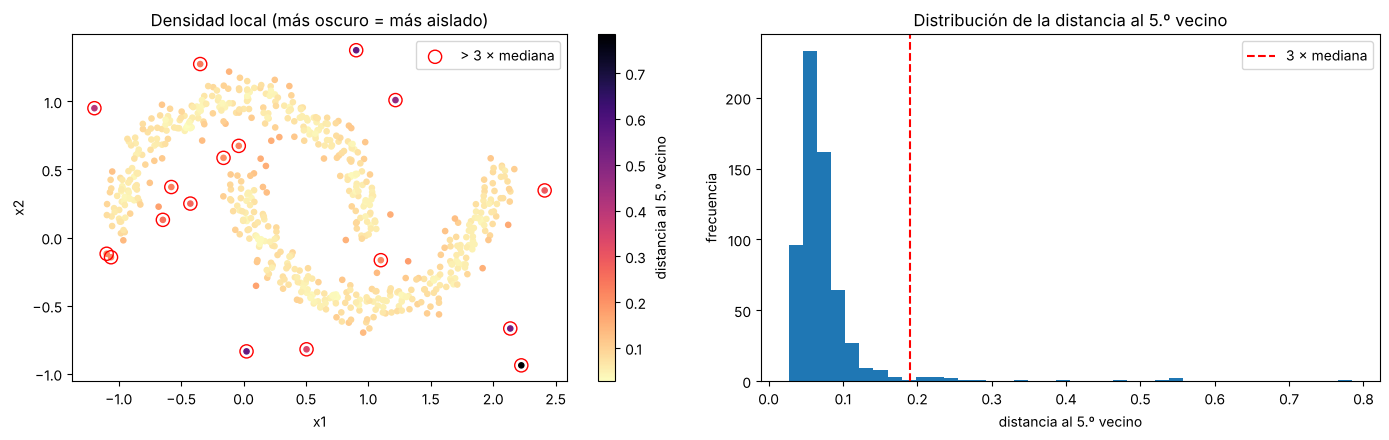

In [5]:
# ¿Por qué la regla IQR no ve nada? Rango observado frente a los límites de la regla
limites = pd.DataFrame({'mínimo': df.min(), 'límite inf. IQR': Q1 - 1.5 * IQR,
                        'máximo': df.max(), 'límite sup. IQR': Q3 + 1.5 * IQR}).round(2)
print(limites)
print(f'\nDesviación estándar: x1 = {df.x1.std():.2f} | x2 = {df.x2.std():.2f} | cociente = {df.x1.std() / df.x2.std():.2f}')

# Criterio multivariado de densidad: distancia de cada punto a su 5.º vecino
# (contando el propio punto, la misma convención que usa DBSCAN con min_samples = 5)
d5 = NearestNeighbors(n_neighbors=5).fit(df).kneighbors(df)[0][:, -1]
umbral_eda = 3 * np.median(d5)
print('\nDistancia al 5.º vecino -> percentiles 50 / 90 / 95 / 99:', np.percentile(d5, [50, 90, 95, 99]).round(3))
print(f'Puntos con distancia > 3 × mediana ({umbral_eda:.3f}):', int((d5 > umbral_eda).sum()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
s_ = ax[0].scatter(df.x1, df.x2, c=d5, cmap='magma_r', s=14)
plt.colorbar(s_, ax=ax[0], label='distancia al 5.º vecino')
ax[0].scatter(df.x1[d5 > umbral_eda], df.x2[d5 > umbral_eda], facecolors='none', edgecolors='red', s=90, label='> 3 × mediana')
ax[0].set_xlabel('x1'); ax[0].set_ylabel('x2'); ax[0].set_title('Densidad local (más oscuro = más aislado)'); ax[0].legend()
ax[1].hist(d5, bins=40); ax[1].axvline(umbral_eda, color='red', ls='--', label='3 × mediana')
ax[1].set_xlabel('distancia al 5.º vecino'); ax[1].set_ylabel('frecuencia')
ax[1].set_title('Distribución de la distancia al 5.º vecino'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación.**

- **Forma:** el gráfico de dispersión muestra dos medias lunas entrelazadas, **no convexas**: el promedio de cada luna cae en su parte cóncava, fuera de la propia luna y cerca de la punta de la otra. Ningún centroide puede representarlas, así que K-Means fallará. Los histogramas son irregulares y tienen varios picos. En x2 aparecen cerca de −0,45 (fondo de la luna inferior), 0,25 (zona donde se cruzan los extremos) y 0,9 (cima de la luna superior). Ninguno separa las dos lunas, porque en cada eje por separado se solapan. La correlación (−0,433) refleja la disposición de las lunas (una arriba a la izquierda y otra abajo a la derecha), no una relación lineal dentro de cada grupo.
- **Atípicos:** la regla IQR **no detecta ninguno**. El rango de x1 (−1,19 a 2,41) y el de x2 (−0,94 a 1,38) quedan dentro de los límites de la regla (−1,80 a 2,77 y −1,58 a 2,11). Los atípicos se generaron dentro del mismo rectángulo que ocupan las lunas: no tienen valores extremos en ninguna variable, sino **combinaciones** de x1 y x2 que caen en zonas vacías del plano. Un criterio **multivariado de densidad** sí los ve: la distancia al 5.º vecino tiene mediana 0,064, pero su percentil 99 es 0,328, y **17 puntos** superan 3 veces la mediana (0,191). En el mapa, esos puntos están aislados en el hueco entre las lunas o fuera de los arcos.
- **Escala:** x1 (desviación 0,88) varía 1,72 veces más que x2 (0,51). Como eps es un radio circular, sin estandarizar cubriría proporcionalmente mucho más de x2, que es justamente la dirección en la que se separan las lunas. Por eso se estandariza (el efecto se mide en los indicadores del Modelo 1).

### Paso 4 — División entrenamiento/prueba y escalado

Aunque no hay variable objetivo, se separa un 30 % de **prueba** para comprobar que la estructura encontrada se mantiene en datos no vistos.

In [6]:
X_tr, X_te, y_tr_ref, y_te_ref = train_test_split(X, y_ref, test_size=0.3, random_state=42)
scaler = StandardScaler().fit(X_tr)   # ajustado solo con entrenamiento
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)
print(Xs_tr.shape, Xs_te.shape)   # (434, 2) (186, 2)

# Comprobación de que no hay fuga: solo el entrenamiento queda con media 0 y desviación 1 exactas
print('Media y desviación aprendidas (solo entrenamiento):', scaler.mean_.round(3), scaler.scale_.round(3))
print('Entrenamiento -> medias:', Xs_tr.mean(axis=0).round(3), '| desviaciones:', Xs_tr.std(axis=0).round(3))
print('Prueba        -> medias:', Xs_te.mean(axis=0).round(3), '| desviaciones:', Xs_te.std(axis=0).round(3))

(434, 2) (186, 2)
Media y desviación aprendidas (solo entrenamiento): [0.506 0.263] [0.876 0.516]
Entrenamiento -> medias: [-0.  0.] | desviaciones: [1. 1.]
Prueba        -> medias: [-0.014 -0.036] | desviaciones: [1.01 0.96]


**Fuga de información (*data leakage*).** El `StandardScaler` aprende la media (0,506; 0,263) y la desviación (0,876; 0,516) **solo** del entrenamiento. Por eso el entrenamiento queda con media 0 y desviación 1 exactas, y la prueba no (medias −0,014 y −0,036; desviaciones 1,01 y 0,96). Si el escalador se ajustara con los 620 puntos, la prueba influiría en el radio efectivo de eps y la evaluación dejaría de ser sobre datos realmente no vistos. La división deja 12 de los 20 atípicos en entrenamiento y 8 en prueba.

### Paso 5 — Selección de min_samples y eps

**min_samples.** La regla práctica es al menos D + 1 = 3 (D = 2 variables). Ester et al. (1996) y Schubert et al. (2017) recomiendan 2·D = 4 para datos 2D; se usa **5**, un poco más, para que un par de atípicos cercanos entre sí no formen una «zona densa».

**eps.** Se elige con el **gráfico de k-distancias**: la distancia de cada punto a su vecino número `min_samples`, ordenada de menor a mayor. Además del percentil que sugiere la guía, el codo se ubica de forma objetiva como el punto de la curva más alejado de la recta que une sus extremos (idea del método *Kneedle*; Satopää et al., 2011).

Percentiles 50/80/90/95/98: [0.114 0.152 0.193 0.24  0.358]
Codo de la curva: punto 408 de 434 (percentil 94.0) -> k-distancia = 0.225


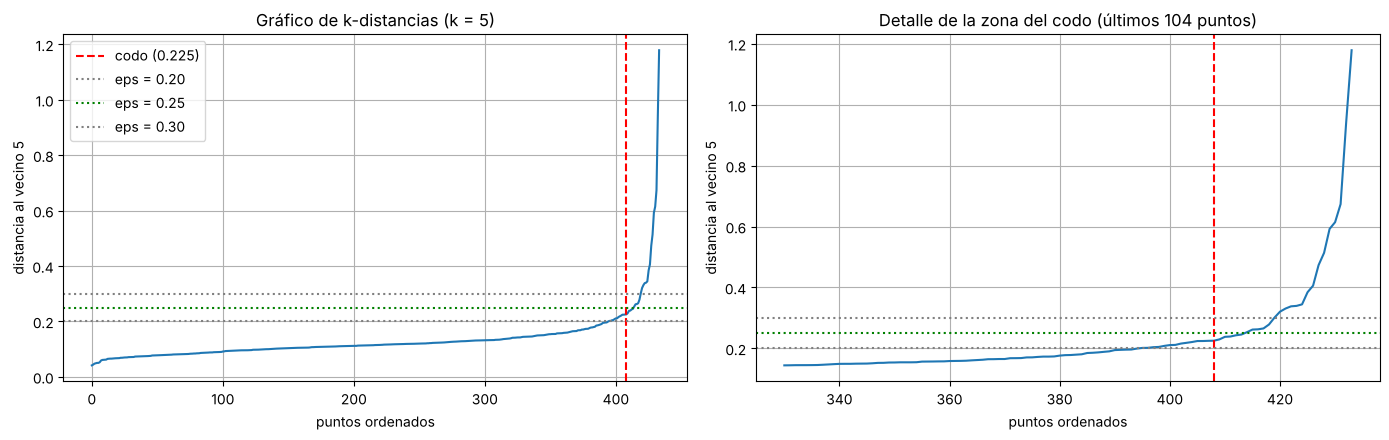

,clusters,ruido %,silueta (sin ruido),tamaños
eps,,,,
0.15,4,9.4,0.371,"[167, 120, 68, 38]"
0.20,3,4.4,0.222,"[202, 173, 40]"
0.25,2,2.8,0.391,"[216, 206]"
0.30,2,2.1,0.389,"[217, 208]"
0.35,1,1.4,NaN,[428]


In [7]:
min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples).fit(Xs_tr)
dist, _ = nn.kneighbors(Xs_tr)
kdist = np.sort(dist[:, -1])

# Codo objetivo: punto de la curva más alejado de la recta que une sus extremos (idea de Kneedle)
xn = np.arange(len(kdist)) / (len(kdist) - 1)
yn = (kdist - kdist[0]) / (kdist[-1] - kdist[0])
i_codo = int(np.argmax(xn - yn))
print('Percentiles 50/80/90/95/98:', np.percentile(kdist, [50, 80, 90, 95, 98]).round(3))
print(f'Codo de la curva: punto {i_codo} de {len(kdist)} (percentil {100 * i_codo / len(kdist):.1f}) -> k-distancia = {kdist[i_codo]:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, desde in zip(ax, [0, 330]):
    a.plot(np.arange(desde, len(kdist)), kdist[desde:])
    a.axvline(i_codo, color='red', ls='--', label=f'codo ({kdist[i_codo]:.3f})')
    for e, c in [(0.20, 'grey'), (0.25, 'green'), (0.30, 'grey')]:
        a.axhline(e, color=c, ls=':', label=f'eps = {e:.2f}')
    a.set_xlabel('puntos ordenados'); a.set_ylabel(f'distancia al vecino {min_samples}'); a.grid()
ax[0].set_title('Gráfico de k-distancias (k = 5)'); ax[1].set_title('Detalle de la zona del codo (últimos 104 puntos)')
ax[0].legend(); plt.tight_layout(); plt.show()

# Barrido de eps usando SOLO criterios internos
filas_barrido = []
for eps in [0.15, 0.20, 0.25, 0.30, 0.35]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit(Xs_tr).labels_
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    m = lab != -1
    sil = silhouette_score(Xs_tr[m], lab[m]) if n_cl > 1 else float('nan')
    filas_barrido.append({'eps': eps, 'clusters': n_cl, 'ruido %': round(100 * np.mean(~m), 1),
                          'silueta (sin ruido)': round(sil, 3), 'tamaños': sorted(np.bincount(lab[m]).tolist(), reverse=True)})
display(pd.DataFrame(filas_barrido).set_index('eps'))

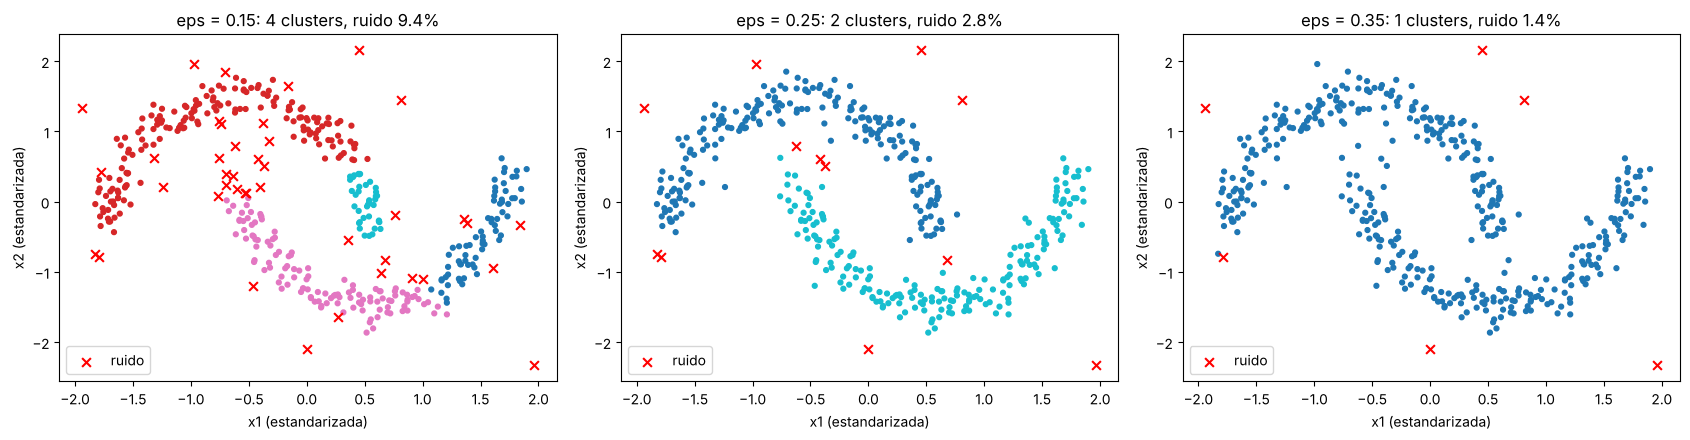

In [8]:
# Qué pasa al variar eps: fragmentación (eps pequeño) y fusión (eps grande)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, eps in zip(ax, [0.15, 0.25, 0.35]):
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit(Xs_tr).labels_
    a.scatter(Xs_tr[lab != -1, 0], Xs_tr[lab != -1, 1], c=lab[lab != -1], cmap='tab10', s=12)
    a.scatter(Xs_tr[lab == -1, 0], Xs_tr[lab == -1, 1], c='red', marker='x', s=40, label='ruido')
    a.set_title(f'eps = {eps:.2f}: {len(set(lab)) - (1 if -1 in lab else 0)} clusters, ruido {np.mean(lab == -1):.1%}')
    a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)'); a.legend(loc='lower left')
plt.tight_layout(); plt.show()

**Elección de eps = 0,25.**

- **k-distancias:** la curva es casi plana hasta el percentil 90 (mediana 0,114; percentil 90: 0,193) y luego sube con fuerza (percentil 98: 0,358). El codo objetivo está en el punto 408 de 434 (percentil 94,0), con k-distancia **0,225**, en línea con el ≈ 0,24 (percentil 95) de la guía. Los puntos a la izquierda del codo viven en zonas densas; los de la derecha están aislados.
- **Barrido con criterios internos:**
  - **eps = 0,15** fragmenta las lunas en 4 trozos (167, 120, 68 y 38 puntos) y marca un 9,4 % como ruido: el radio es menor que la separación típica en los tramos menos densos, y la cadena de núcleos se corta.
  - **eps = 0,20** todavía parte una luna en dos (202, 173 y 40) y tiene la peor silueta (0,222).
  - **eps = 0,25 y 0,30** dan 2 clusters con silueta casi igual (0,391 y 0,389).
  - **eps = 0,35** fusiona todo en un solo cluster (428 puntos): el radio supera la distancia entre la punta de una luna y la otra, y la cadena de vecindad las une.
- **Decisión:** eps = 0,25, que tiene la mejor silueta, está pegado al codo y deja más margen frente a la fusión que 0,30. El 2,8 % de ruido es coherente con la proporción de atípicos esperable (20 / 620 = 3,2 %). La decisión no usó la etiqueta.

### Paso 6 — Entrenamiento del modelo

{-1: 12, 0: 216, 1: 206}
Puntos núcleo: 414
cluster   -1    0    1  total
tipo                         
frontera   0    3    5      8
núcleo     0  213  201    414
ruido     12    0    0     12
total     12  216  206    434


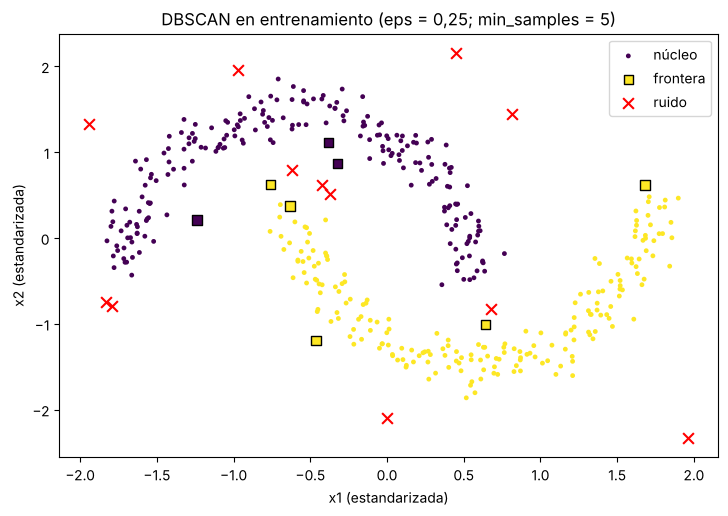

In [9]:
eps = 0.25
dbscan = DBSCAN(eps=eps, min_samples=min_samples).fit(Xs_tr)
lab_tr = dbscan.labels_
etq, cnt = np.unique(lab_tr, return_counts=True)
print(dict(zip(etq.tolist(), cnt.tolist())))   # {-1: 12, 0: 216, 1: 206}
print('Puntos núcleo:', len(dbscan.core_sample_indices_))   # 414

# Tipo de cada punto: núcleo, frontera o ruido
es_nucleo = np.zeros(len(lab_tr), dtype=bool); es_nucleo[dbscan.core_sample_indices_] = True
tipo_tr = np.where(es_nucleo, 'núcleo', np.where(lab_tr == -1, 'ruido', 'frontera'))
print(pd.crosstab(tipo_tr, lab_tr, rownames=['tipo'], colnames=['cluster'], margins=True, margins_name='total'))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for t, mk, sz in [('núcleo', 'o', 12), ('frontera', 's', 45)]:
    m = tipo_tr == t
    ax.scatter(Xs_tr[m, 0], Xs_tr[m, 1], c=lab_tr[m], cmap='viridis', vmin=0, vmax=1, marker=mk, s=sz,
               edgecolors='black' if t == 'frontera' else 'none', label=t)
ax.scatter(Xs_tr[lab_tr == -1, 0], Xs_tr[lab_tr == -1, 1], c='red', marker='x', s=60, label='ruido')
ax.set_xlabel('x1 (estandarizada)'); ax.set_ylabel('x2 (estandarizada)')
ax.legend(); ax.set_title('DBSCAN en entrenamiento (eps = 0,25; min_samples = 5)'); plt.show()

**Resultado.** DBSCAN encuentra **2 clusters** (216 y 206 puntos) y **12 puntos de ruido** (2,8 %). De los 434 puntos, **414 son núcleo** (95,4 %), **8 frontera** (3 del cluster 0 y 5 del cluster 1) y 12 ruido. Hay pocos puntos frontera porque cada luna tiene densidad casi uniforme: casi todos sus puntos tienen al menos 5 vecinos a menos de 0,25. Los puntos frontera (cuadrados) quedan en los bordes de las lunas: están algo separados de la nube, pero dentro del radio de un núcleo. En el Paso 8 se verifica que 7 son puntos de las lunas y 1 es un atípico real. El ruido (cruces rojas) son puntos aislados en el hueco entre las lunas y alrededor de ellas.

### Paso 7 — Testeo y validación

DBSCAN **no tiene `predict()`**: el modelo es la propia partición del entrenamiento. Para asignar la prueba se entrena un 1-NN con los **puntos núcleo** y sus etiquetas, y si un punto nuevo está a más de eps de todo núcleo se marca como ruido (Géron, 2019). Así se reproduce la regla de DBSCAN: un punto nuevo dentro del radio de un núcleo sería frontera de ese cluster; si no, es ruido.

Entrenamiento: {'clusters': 2, 'ruido_%': 2.8, 'silueta': 0.391, 'davies_bouldin': 1.006, 'calinski_harabasz': 372.6}
Prueba       : {'clusters': 2, 'ruido_%': 2.7, 'silueta': 0.384, 'davies_bouldin': 1.024, 'calinski_harabasz': 154.9}

Silueta tratando el ruido como cluster -> entrenamiento: 0.312 | prueba: 0.311


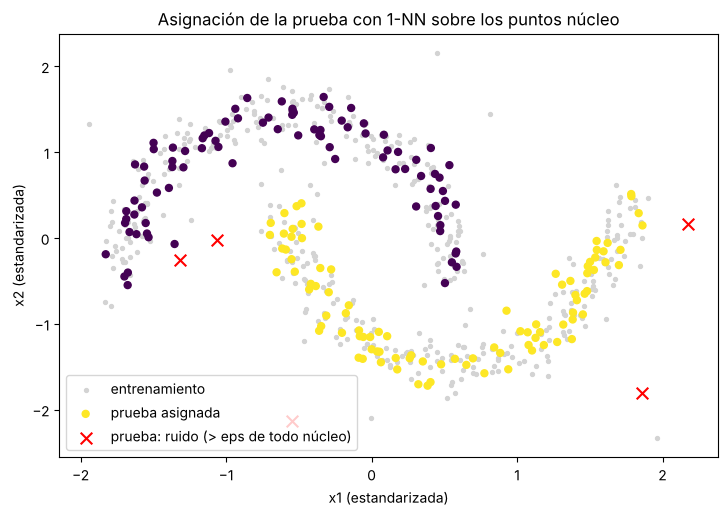

In [10]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(dbscan.components_, lab_tr[dbscan.core_sample_indices_])
d, _ = knn.kneighbors(Xs_te, n_neighbors=1)
lab_te = knn.predict(Xs_te)
lab_te[d[:, 0] > eps] = -1   # lejos de todo núcleo = ruido

def metricas(Xs, lab):
    m = lab != -1   # las métricas internas excluyen el ruido
    return {'clusters': len(set(lab[m])), 'ruido_%': float(round(100 * np.mean(~m), 1)),
            'silueta': round(silhouette_score(Xs[m], lab[m]), 3),
            'davies_bouldin': round(davies_bouldin_score(Xs[m], lab[m]), 3),
            'calinski_harabasz': round(calinski_harabasz_score(Xs[m], lab[m]), 1)}

print('Entrenamiento:', metricas(Xs_tr, lab_tr))
print('Prueba       :', metricas(Xs_te, lab_te))

# Contraste: ¿qué pasaría si el ruido se tratara como un cluster más?
print('\nSilueta tratando el ruido como cluster -> entrenamiento:', round(silhouette_score(Xs_tr, lab_tr), 3),
      '| prueba:', round(silhouette_score(Xs_te, lab_te), 3))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(Xs_tr[:, 0], Xs_tr[:, 1], c='lightgrey', s=8, label='entrenamiento')
ax.scatter(Xs_te[lab_te != -1, 0], Xs_te[lab_te != -1, 1], c=lab_te[lab_te != -1], cmap='viridis', s=25, label='prueba asignada')
ax.scatter(Xs_te[lab_te == -1, 0], Xs_te[lab_te == -1, 1], c='red', marker='x', s=70, label='prueba: ruido (> eps de todo núcleo)')
ax.set_xlabel('x1 (estandarizada)'); ax.set_ylabel('x2 (estandarizada)')
ax.legend(); ax.set_title('Asignación de la prueba con 1-NN sobre los puntos núcleo'); plt.show()

**Cómo leer estos resultados.**

- **Generalización:** el ruido (2,8 % → 2,7 %), la silueta (0,391 → 0,384) y Davies-Bouldin (Davies & Bouldin, 1979; 1,006 → 1,024) son casi iguales en entrenamiento y prueba: la estructura **generaliza**. Calinski-Harabasz (372,6 → 154,9) crece con el número de puntos (Caliński & Harabasz, 1974) y no se compara entre conjuntos de distinto tamaño.
- **Silueta moderada (≈ 0,39) aunque la separación es correcta:** la silueta compara la distancia media de un punto a su propio grupo con la del grupo vecino (Rousseeuw, 1987). En una luna curva, los puntos de una punta están lejos de los de la otra punta de su misma luna y, en cambio, cerca de la otra luna, así que la silueta **penaliza las formas curvas**. En el Paso 8 se ve que K-Means, con una partición equivocada, obtiene una silueta mayor (0,483). Por eso no puede ser el único criterio con DBSCAN.
- **Ruido fuera de las métricas:** si el ruido se tratara como un cluster más, la silueta bajaría a 0,312 (entrenamiento) y 0,311 (prueba), porque esos puntos dispersos no forman un grupo cohesionado.

### Paso 8 — Métricas del modelo, validación externa y anomalías

Solo ahora, con el modelo ya elegido y entrenado, se compara con la etiqueta de referencia.

In [11]:
print('ARI prueba:', round(adjusted_rand_score(y_te_ref, lab_te), 3))
print('NMI prueba:', round(normalized_mutual_info_score(y_te_ref, lab_te), 3))
print(pd.crosstab(y_te_ref, lab_te, rownames=['real'], colnames=['dbscan']))
atip_real = y_te_ref == -1
atip_pred = lab_te == -1
print('Atípicos reales:', atip_real.sum(), '| detectados:', (atip_pred & atip_real).sum(),
      '| falsas alarmas:', (atip_pred & ~atip_real).sum())
# Línea base: K-Means con k = 2
km = KMeans(2, n_init=10, random_state=42).fit(Xs_tr)
print('K-Means ARI prueba:', round(adjusted_rand_score(y_te_ref, km.predict(Xs_te)), 3))

ARI prueba: 0.967
NMI prueba: 0.927
dbscan  -1   0   1
real              
-1       5   2   1
 0       0  85   0
 1       0   0  93
Atípicos reales: 8 | detectados: 5 | falsas alarmas: 0
K-Means ARI prueba: 0.456


Anomalías DBSCAN (prueba)        : {'atípicos reales': 8, 'detectados': 5, 'falsas alarmas': 0, 'precisión': 1.0, 'exhaustividad': 0.625}
Anomalías DBSCAN (entrenamiento) : {'atípicos reales': 12, 'detectados': 6, 'falsas alarmas': 6, 'precisión': 0.5, 'exhaustividad': 0.5}
Tipo de punto en entrenamiento frente a la etiqueta real:
real      atípico real  luna
tipo                        
frontera             1     7
núcleo               5   409
ruido                6     6
Distancia al núcleo más cercano de los 8 atípicos de prueba: [0.3   0.319 0.17  0.036 0.174 0.326 0.682 0.92 ]
ARI de DBSCAN solo sobre los puntos de las lunas (sin los 8 atípicos): 1.0

K-Means (k = 2) en prueba -> NMI: 0.349 | silueta: 0.483
k-means   0   1
real           
-1        5   3
 0       74  11
 1       15  78


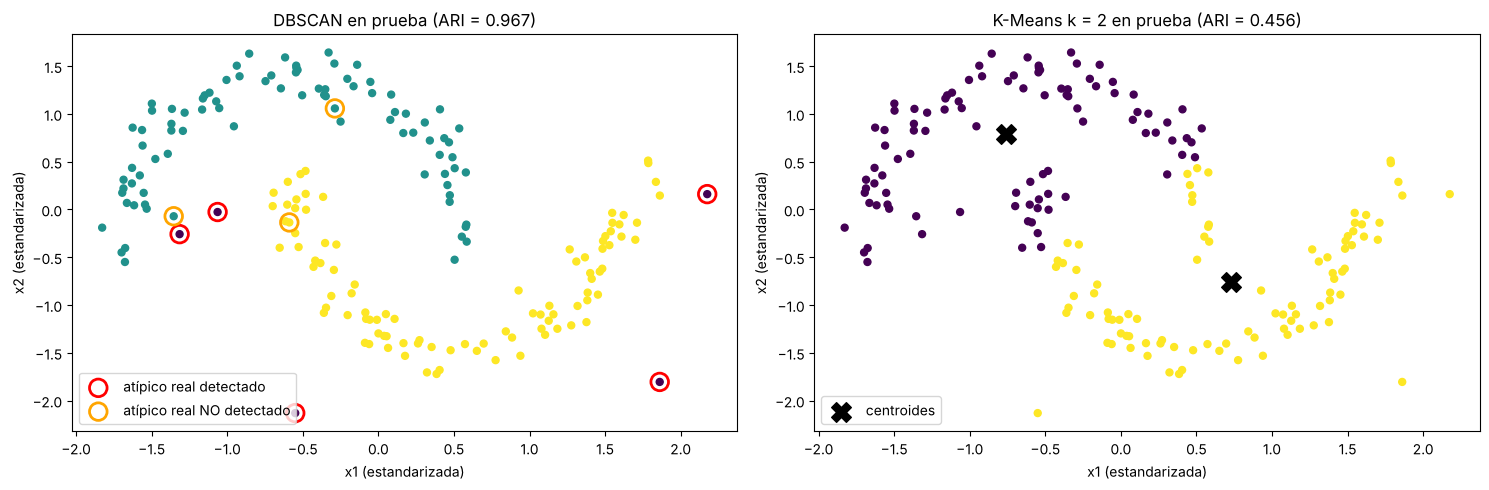

In [12]:
def resumen_anomalias(y_ref_, es_anom):
    real = y_ref_ == -1
    vp, fp = int((es_anom & real).sum()), int((es_anom & ~real).sum())
    return {'atípicos reales': int(real.sum()), 'detectados': vp, 'falsas alarmas': fp,
            'precisión': float(round(vp / max(es_anom.sum(), 1), 3)), 'exhaustividad': float(round(vp / real.sum(), 3))}

print('Anomalías DBSCAN (prueba)        :', resumen_anomalias(y_te_ref, lab_te == -1))
print('Anomalías DBSCAN (entrenamiento) :', resumen_anomalias(y_tr_ref, lab_tr == -1))
print('Tipo de punto en entrenamiento frente a la etiqueta real:')
print(pd.crosstab(tipo_tr, np.where(y_tr_ref == -1, 'atípico real', 'luna'), rownames=['tipo'], colnames=['real']))
print('Distancia al núcleo más cercano de los 8 atípicos de prueba:', d[atip_real, 0].round(3))
print('ARI de DBSCAN solo sobre los puntos de las lunas (sin los 8 atípicos):',
      round(adjusted_rand_score(y_te_ref[~atip_real], lab_te[~atip_real]), 3))

lab_km = km.predict(Xs_te)
print('\nK-Means (k = 2) en prueba -> NMI:', round(normalized_mutual_info_score(y_te_ref, lab_km), 3),
      '| silueta:', round(silhouette_score(Xs_te, lab_km), 3))
print(pd.crosstab(y_te_ref, lab_km, rownames=['real'], colnames=['k-means']))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(Xs_te[:, 0], Xs_te[:, 1], c=np.where(lab_te == -1, -1, lab_te), cmap='viridis', s=25)
ax[0].scatter(Xs_te[atip_real & atip_pred, 0], Xs_te[atip_real & atip_pred, 1], facecolors='none', edgecolors='red', s=160, lw=2, label='atípico real detectado')
ax[0].scatter(Xs_te[atip_real & ~atip_pred, 0], Xs_te[atip_real & ~atip_pred, 1], facecolors='none', edgecolors='orange', s=160, lw=2, label='atípico real NO detectado')
ax[0].set_title(f'DBSCAN en prueba (ARI = {adjusted_rand_score(y_te_ref, lab_te):.3f})')
ax[1].scatter(Xs_te[:, 0], Xs_te[:, 1], c=lab_km, cmap='viridis', s=25)
ax[1].scatter(*km.cluster_centers_.T, c='black', marker='X', s=200, label='centroides')
ax[1].set_title(f'K-Means k = 2 en prueba (ARI = {adjusted_rand_score(y_te_ref, lab_km):.3f})')
for a in ax: a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)'); a.legend(loc='lower left')
plt.tight_layout(); plt.show()

**Resultado.**

- **Clustering:** ARI = **0,967** (Hubert & Arabie, 1985) y NMI = **0,927** (Strehl & Ghosh, 2002). La tabla cruzada muestra que DBSCAN recupera las dos lunas **sin ningún error entre ellas** (85 y 93 puntos). Medido solo sobre los puntos de las lunas, el ARI es 1,000. Lo único que baja el ARI son los 3 atípicos absorbidos por una luna.
- **Anomalías en prueba:** detecta **5 de los 8 atípicos sin ninguna falsa alarma** (precisión 1,00; exhaustividad 0,625). Los 3 no detectados están a 0,170, 0,036 y 0,174 del núcleo más cercano, por debajo de eps: cayeron por azar pegados a una luna y, por densidad, son indistinguibles de ella. El de 0,036 está prácticamente sobre la luna.
- **Anomalías en entrenamiento:** 6 de 12 atípicos quedan como ruido, con 6 falsas alarmas (puntos de las lunas que el ruido gaussiano dejó algo separados). La tabla de tipos muestra que 5 atípicos reales llegaron a ser **núcleo** (cayeron dentro de una luna) y 1 quedó como frontera.
- **Línea base K-Means (k = 2):** ARI 0,456 y NMI 0,349. Corta las lunas con una línea recta (11 puntos de la luna 0 y 15 de la luna 1 quedan del lado equivocado) y asigna los 8 atípicos a algún grupo, porque no tiene noción de ruido. Aun así, su silueta (0,483) es **mayor** que la de DBSCAN: la silueta premia los grupos convexos.

### Indicadores del Modelo 1

Para que las configuraciones sean comparables, **todas las métricas internas se calculan en el mismo espacio estandarizado** (`Xs_tr`/`Xs_te`) y excluyendo el ruido, incluso para el modelo entrenado sin escalar. La prueba se asigna siempre con el 1-NN sobre núcleos y el umbral eps de cada configuración. Las columnas que pide la guía se miden en la prueba; a la derecha se agregan las de entrenamiento.

In [13]:
def asignar_prueba(modelo, lab, Xte_, eps_):
    """1-NN sobre los puntos núcleo; a más de eps de todo núcleo -> ruido."""
    k1 = KNeighborsClassifier(n_neighbors=1).fit(modelo.components_, lab[modelo.core_sample_indices_])
    dd, _ = k1.kneighbors(Xte_, n_neighbors=1)
    lt = k1.predict(Xte_); lt[dd[:, 0] > eps_] = -1
    return lt

def metricas_seguras(Xs, lab):
    m = lab != -1
    if len(set(lab[m])) < 2:   # con un solo cluster la silueta y DB no están definidas
        return {'clusters': len(set(lab[m])), 'ruido_%': round(100 * np.mean(~m), 1),
                'silueta': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return metricas(Xs, lab)

def fila_dbscan(nombre, eps_, ms_, Xtr_modelo, Xte_modelo):
    mod = DBSCAN(eps=eps_, min_samples=ms_).fit(Xtr_modelo)
    l_tr = mod.labels_
    l_te = asignar_prueba(mod, l_tr, Xte_modelo, eps_)
    m_tr, m_te = metricas_seguras(Xs_tr, l_tr), metricas_seguras(Xs_te, l_te)   # siempre en el espacio estandarizado
    an = resumen_anomalias(y_te_ref, l_te == -1)
    n_nuc = len(mod.core_sample_indices_); n_rui = int((l_tr == -1).sum())
    return {'Configuración': nombre, 'Clusters': m_te['clusters'], 'Ruido % (test)': m_te['ruido_%'],
            'Silueta (test)': m_te['silueta'], 'DB (test)': m_te['davies_bouldin'],
            'ARI ext. (test)': round(adjusted_rand_score(y_te_ref, l_te), 3),
            'NMI ext. (test)': round(normalized_mutual_info_score(y_te_ref, l_te), 3),
            'Atípicos detect. (test)': f"{an['detectados']} de {an['atípicos reales']} ({an['falsas alarmas']} falsas)",
            'Ruido % (train)': m_tr['ruido_%'], 'Silueta (train)': m_tr['silueta'],
            'Núcleo / frontera / ruido (train)': f'{n_nuc} / {len(l_tr) - n_nuc - n_rui} / {n_rui}'}

configs = [('eps = 0,20 · min_samples = 5', 0.20, 5, Xs_tr, Xs_te),
           ('eps = 0,25 · min_samples = 5 (elegido)', 0.25, 5, Xs_tr, Xs_te),
           ('eps = 0,30 · min_samples = 5', 0.30, 5, Xs_tr, Xs_te),
           ('eps = 0,25 · min_samples = 10', 0.25, 10, Xs_tr, Xs_te),
           ('eps = 0,25 · sin escalar', 0.25, 5, X_tr, X_te)]
indicadores_m1 = pd.DataFrame([fila_dbscan(*c) for c in configs]).set_index('Configuración')
display(indicadores_m1)

# Modelo sin escalar: ¿qué radio representa eps = 0,25 en cada eje estandarizado?
print('eps = 0,25 en unidades originales equivale a', np.round(0.25 / scaler.scale_, 3), 'desviaciones de (x1, x2)')
lab_raw = DBSCAN(eps=0.25, min_samples=5).fit(X_tr).labels_
print('Sin escalar -> etiquetas en entrenamiento:', dict(zip(*[a.tolist() for a in np.unique(lab_raw, return_counts=True)])))

,Clusters,Ruido % (test),Silueta (test),DB (test),ARI ext. (test),NMI ext. (test),Atípicos detect. (test),Ruido % (train),Silueta (train),Núcleo / frontera / ruido (train)
Configuración,,,,,,,,,,
"eps = 0,20 · min_samples = 5",3,5.4,0.182,1.339,0.813,0.751,5 de 8 (5 falsas),4.4,0.222,395 / 20 / 19
"eps = 0,25 · min_samples = 5 (elegido)",2,2.7,0.384,1.024,0.967,0.927,5 de 8 (0 falsas),2.8,0.391,414 / 8 / 12
"eps = 0,30 · min_samples = 5",2,2.2,0.382,1.029,0.957,0.912,4 de 8 (0 falsas),2.1,0.389,419 / 6 / 9
"eps = 0,25 · min_samples = 10",2,3.2,0.383,1.029,0.956,0.901,5 de 8 (1 falsas),3.0,0.395,376 / 45 / 13
"eps = 0,25 · sin escalar",1,2.2,NaN,NaN,0.068,0.157,4 de 8 (0 falsas),1.2,NaN,426 / 3 / 5


eps = 0,25 en unidades originales equivale a [0.285 0.485] desviaciones de (x1, x2)
Sin escalar -> etiquetas en entrenamiento: {-1: 5, 0: 429}


**Interpretación.**

- **eps = 0,25 · min_samples = 5 (elegido)** es el mejor en todas las columnas de prueba: silueta 0,384, Davies-Bouldin 1,024, ARI 0,967 y 5 de 8 atípicos sin falsas alarmas.
- **eps = 0,20** fragmenta una luna (3 clusters), sube el ruido al 5,4 % y la mitad de lo que marca como ruido son puntos de las lunas (5 falsas alarmas). La silueta (0,182) y DB (1,339) detectan el error sin usar etiquetas.
- **eps = 0,30** da casi la misma partición (ARI 0,957), pero el radio mayor absorbe un atípico más (4 de 8). Es el compromiso típico de DBSCAN: **más eps, menos ruido y menos anomalías detectadas**.
- **min_samples = 10** exige más densidad: los núcleos bajan de 414 a 376 y los puntos frontera suben de 8 a 45, porque muchos antiguos núcleos ya no tienen 10 vecinos pero siguen cerca de uno. La partición casi no cambia (ARI 0,956), con 1 falsa alarma. El resultado es robusto entre 5 y 10.
- **Sin escalar:** un solo cluster (429 puntos + 5 de ruido) y ARI 0,068. Un radio de 0,25 en unidades originales equivale a 0,285 desviaciones de x1, pero a **0,485 de x2**: en la dirección vertical, donde está el hueco entre las lunas, el radio es casi el doble y conecta ambas lunas. Esto confirma que escalar era necesario.

Esta tabla es una verificación: eps y min_samples ya se habían elegido en el Paso 5 con criterios internos.

# Parte B — Modelo 2: Modelo de Mezcla Gaussiana (reto)

Un GMM supone que los datos provienen de **K distribuciones normales** mezcladas: $p(x) = \sum_k \pi_k\,\mathcal{N}(x \mid \mu_k, \Sigma_k)$, con $\sum_k \pi_k = 1$. Se ajusta con el algoritmo **EM** (Dempster et al., 1977). El paso E calcula la responsabilidad $\gamma_{ik}$ de cada componente sobre cada punto. El paso M recalcula $\pi_k$, $\mu_k$ y $\Sigma_k$ como promedios ponderados por $\gamma$. Se repite hasta que la log-verosimilitud deja de crecer (Bishop, 2006; Murphy, 2012). El tipo de covarianza define la forma de cada componente:

- **full:** cada componente tiene su propia elipse, con cualquier orientación.
- **tied:** todas comparten la misma elipse.
- **diag:** elipses alineadas con los ejes.
- **spherical:** círculos.

K y el tipo de covarianza se eligen con **BIC** (Schwarz, 1978) o **AIC** (Akaike, 1974).

## B.1 Diseño del procedimiento (propio)

| # | Paso | Decisión | Justificación |
|---|---|---|---|
| 1 | **Datos** | Reutilizar `Xs_tr` y `Xs_te` del Paso 4 (misma división 70/30 y mismo `StandardScaler`, ajustado solo con entrenamiento). | Comparación justa con DBSCAN y sin fuga. Además, las covarianzas `diag` y `spherical` no son invariantes a la escala. |
| 2 | **EDA del supuesto** | Ajustar una sola gaussiana (K = 1), dibujar su elipse de 2σ, medir qué fracción de puntos cae dentro (una normal 2D tendría 86,5 %) y cuántos puntos hay cerca de su centro. | El supuesto central del GMM es que cada grupo es aproximadamente una elipse. Si una elipse no describe una luna, se anticipa que harán falta varias componentes por luna. |
| 3 | **Grilla de selección** | K = 1…8 × {full, tied, diag, spherical}, `n_init=5`, `random_state=42`. Registrar BIC, AIC, número de parámetros y convergencia, y graficar BIC y AIC frente a K. | EM converge a óptimos locales, y `n_init=5` conserva la mejor de 5 inicializaciones. BIC y AIC equilibran ajuste y complejidad; la inercia y la silueta no sirven para elegir K en un GMM (Géron, 2019). |
| 4 | **Borde de la grilla** | Si el menor BIC cae en K = 8, ampliar la búsqueda hasta K = 15 (full). | Confirmar que es un mínimo real y no un efecto del límite de la grilla. |
| 5 | **Dos candidatos** | `g_bic` (menor BIC global) y `g_2` (K = 2, full). | `g_bic` es el mejor modelo de **densidad** según los datos. `g_2` impone **un grupo por luna** con la covarianza más flexible. Compararlos separa «describir la densidad» de «encontrar los grupos». |
| 6 | **Revisión del ajuste** | `converged_`, `n_iter_`, `weights_` y `means_` (en escala estandarizada y original). Se marcan las componentes con peso < 2 %. | Una componente diminuta describe muy pocos puntos y puede estar «atrapando» atípicos, lo que afecta la detección de anomalías. |
| 7 | **Asignación de la prueba** | `predict()` (componente más probable) y `predict_proba()`; p_max = probabilidad máxima de cada punto; contar p_max < 0,8 y ubicar esos puntos en el plano. | La asignación probabilística es la ventaja central del GMM: cuantifica la duda en las fronteras. |
| 8 | **Anomalías** | `score_samples()` (log-densidad). Umbral = percentil 4 de la log-densidad del entrenamiento; un punto de prueba es anómalo si queda por debajo. Contar aciertos, falsas alarmas, precisión y exhaustividad en prueba (y en entrenamiento como control). | El 4 % cubre la proporción esperable de atípicos (3,2 %) con un margen. El umbral se fija solo con el entrenamiento y sin etiquetas. |
| 9 | **Métricas** | Silueta, Davies-Bouldin y Calinski-Harabasz en prueba con todos los puntos (el GMM no tiene etiqueta de ruido); ARI y NMI frente a la referencia. Extra: ARI marcando las anomalías como −1. | Son las mismas métricas de la Parte A. La versión con −1 hace al GMM comparable con DBSCAN, que sí separa el ruido. |
| 10 | **Visualización** | Elipses de 2σ de cada componente (descomposición en valores propios de Σₖ), regiones de decisión de `predict` sobre una malla y mapa de log-densidad con el contorno del umbral. | Muestra cómo se aproxima cada luna con elipses y dónde caen las anomalías. |

### Pseudocódigo

```text
ENTRADA:    Xs_tr, Xs_te (escalados con el scaler del Paso 4), y_te_ref (solo validación externa)
PARÁMETROS: tipos = [full, tied, diag, spherical], K_max = 8, p_umbral = 4, p_incierto = 0,8

g1 ← GMM(K = 1, full).ajustar(Xs_tr)
REPORTAR % de puntos dentro de la elipse de 2σ de g1 y puntos cerca de su centro   # ¿elipse?

PARA cov EN tipos:
    PARA K DESDE 1 HASTA K_max:
        g ← GMM(K, cov, n_init = 5, semilla = 42).ajustar(Xs_tr)
        REGISTRAR cov, K, BIC(g), AIC(g), n_parámetros(g), convergió(g)
GRAFICAR BIC y AIC frente a K, una curva por tipo de covarianza
SI argmin_K BIC = K_max: REPETIR con K hasta 15 (full) para confirmar el mínimo

g_bic ← modelo con menor BIC;  g_2 ← GMM(K = 2, full)                  # decisión SIN etiquetas

PARA g EN [g_bic, g_2]:
    REVISAR convergió(g), iteraciones(g), pesos(g), medias(g); MARCAR pesos < 2 %
    lab_te ← g.predecir(Xs_te)
    p_max  ← max_k g.predecir_proba(Xs_te)
    umbral ← percentil(g.log_verosimilitud(Xs_tr), 4)
    anom   ← g.log_verosimilitud(Xs_te) < umbral
    REPORTAR silueta, DB, CH (Xs_te, lab_te); ARI, NMI (y_te_ref, lab_te)
    REPORTAR ARI(y_te_ref, lab_te con anom = −1)
    REPORTAR aciertos, falsas alarmas, precisión y exhaustividad de anom; nº de puntos con p_max < 0,8
    DIBUJAR elipses de 2σ, regiones de decisión y mapa de log-densidad con el contorno del umbral
```

## B.2 Dataset y EDA: ¿los grupos parecen elipses?

Se reutilizan `Xs_tr` y `Xs_te`. Se ajusta una sola gaussiana para ver qué tan lejos están los datos del supuesto del GMM.

Dentro de la elipse de 2 desviaciones: 93.8% de los puntos (una normal 2D tendría 86.5%)
Puntos a menos de 0,3 del centro de esa gaussiana: 0 (si la densidad fuera uniforme en el área ocupada se esperarían varios más; el centro cae entre las lunas)
Correlación x1-x2 en el entrenamiento estandarizado: -0.439


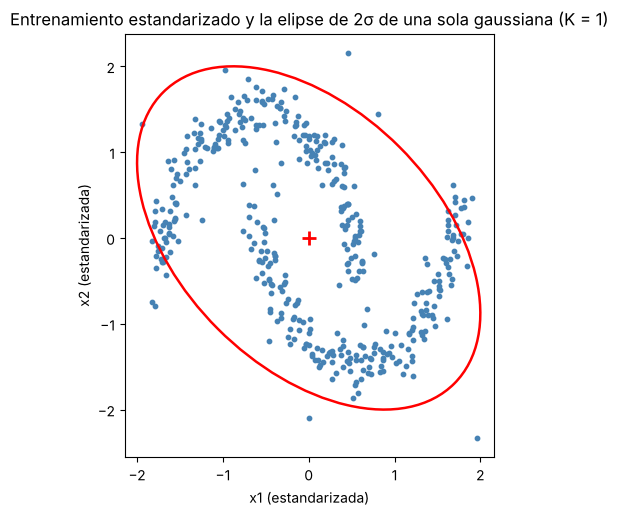

In [14]:
import time
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from matplotlib.patches import Ellipse

def cov_componente(g, k):
    """Matriz de covarianza 2×2 de la componente k, para cualquier tipo de covarianza."""
    c = g.covariances_
    return {'full': lambda: c[k], 'tied': lambda: c, 'diag': lambda: np.diag(c[k]),
            'spherical': lambda: np.eye(2) * c[k]}[g.covariance_type]()

def dibujar_elipses(ax, g, color='black', n_sd=2, etiquetas=False):
    """Elipse de n_sd desviaciones de cada componente; la opacidad crece con el peso."""
    for k in range(g.n_components):
        vals, vecs = np.linalg.eigh(cov_componente(g, k))
        ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
        ax.add_patch(Ellipse(g.means_[k], 2 * n_sd * np.sqrt(vals[1]), 2 * n_sd * np.sqrt(vals[0]), angle=ang,
                             fill=False, color=color, lw=1.8, alpha=0.35 + 0.65 * g.weights_[k] / g.weights_.max()))
        ax.plot(*g.means_[k], '+', color=color, ms=10, mew=2)
        if etiquetas:
            ax.annotate(f'{k} ({g.weights_[k]:.1%})', g.means_[k], xytext=(6, 6), textcoords='offset points', fontsize=9)

# ¿Los datos forman elipses? Se ajusta UNA sola gaussiana y se compara con lo que esperaría una normal
g1 = GaussianMixture(1, covariance_type='full', random_state=42).fit(Xs_tr)
diff = Xs_tr - g1.means_[0]
mahal2 = np.einsum('ij,jk,ik->i', diff, np.linalg.inv(g1.covariances_[0]), diff)
print(f'Dentro de la elipse de 2 desviaciones: {np.mean(mahal2 <= 4):.1%} de los puntos (una normal 2D tendría {1 - np.exp(-2):.1%})')
vecinos_centro = int((np.linalg.norm(diff, axis=1) < 0.3).sum())
print(f'Puntos a menos de 0,3 del centro de esa gaussiana: {vecinos_centro} '
      f'(si la densidad fuera uniforme en el área ocupada se esperarían varios más; el centro cae entre las lunas)')
print('Correlación x1-x2 en el entrenamiento estandarizado:', round(np.corrcoef(Xs_tr.T)[0, 1], 3))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(Xs_tr[:, 0], Xs_tr[:, 1], s=10, c='steelblue')
dibujar_elipses(ax, g1, color='red')
ax.set_xlabel('x1 (estandarizada)'); ax.set_ylabel('x2 (estandarizada)')
ax.set_title('Entrenamiento estandarizado y la elipse de 2σ de una sola gaussiana (K = 1)')
ax.set_aspect('equal'); plt.show()

**Interpretación.** Una sola elipse describe mal los datos:

- El **93,8 %** de los puntos cae dentro de su elipse de 2σ, frente al 86,5 % que tendría una normal. Los datos no tienen las colas de una gaussiana: están confinados en dos franjas.
- El centro de esa gaussiana, que es donde el modelo pone la **máxima** densidad, cae en el hueco entre las lunas: **no hay ningún punto a menos de 0,3** de él.

Cada luna es un **arco**, no una elipse. Pero un arco se puede aproximar con una cadena de elipses pequeñas y alargadas, una por tramo. Esto anticipa que el BIC pedirá **varias componentes por luna**.

## B.3 Selección de componentes con BIC y AIC

$\text{BIC} = -2\ln \hat L + p\ln n$ y $\text{AIC} = -2\ln \hat L + 2p$, donde $p$ es el número de parámetros. Con covarianza full en 2D, cada componente aporta 2 medias, 3 covarianzas y 1 peso, así que $p = 6K - 1$.

Grilla de 32 modelos (n_init = 5) entrenada en 0.82 s | todos convergieron: True

BIC (filas: K; columnas: tipo de covarianza)
cov    full    tied    diag  spherical
K                                     
1    2400.5  2400.5  2487.6     2481.5
2    2294.0  2277.0  2313.3     2302.3
3    2251.9  2292.0  2169.0     2225.9
4    2207.1  2191.3  2220.3     2273.3
5    1970.9  2208.6  2098.7     2190.4
6    1812.6  2154.5  1951.3     2144.5
7    1796.8  2117.8  1931.6     2103.3
8    1782.4  2054.1  1917.0     2091.5

AIC
cov    full    tied    diag  spherical
K                                     
1    2380.2  2380.2  2471.3     2469.3
2    2249.2  2244.4  2276.6     2273.8
3    2182.7  2247.2  2111.9     2181.1
4    2113.5  2134.3  2142.9     2212.3
5    1852.8  2139.4  2001.0     2113.0
6    1670.1  2073.0  1833.2     2050.8
7    1629.8  2024.1  1793.2     1993.3
8    1590.9  1948.2  1758.1     1965.2

Menor BIC: K = 8, cov = full (BIC = 1782.4, 47 parámetros)
Menor AIC: K = 8, cov = full

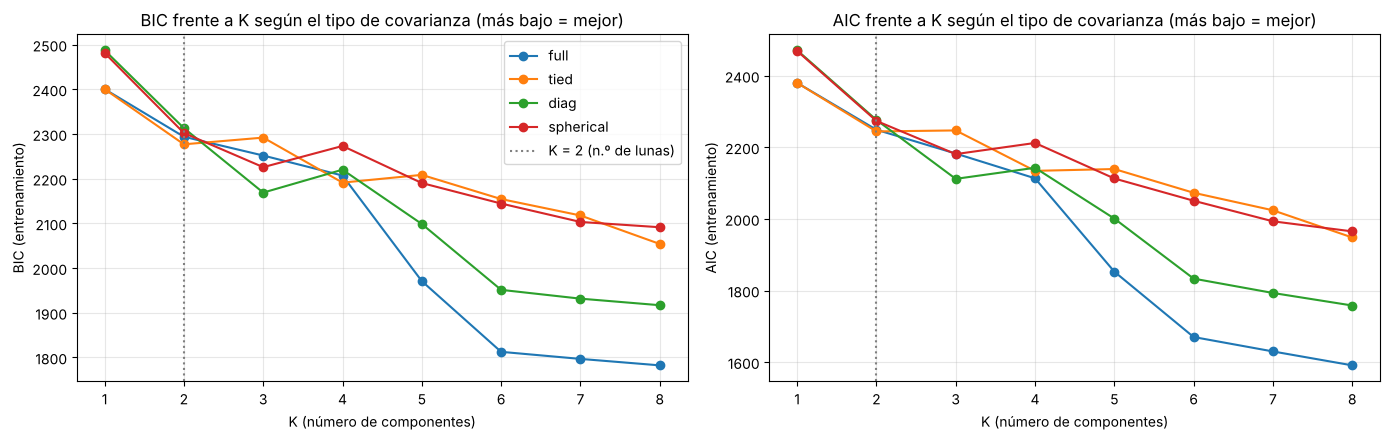

In [15]:
TIPOS_COV = ['full', 'tied', 'diag', 'spherical']
modelos_gmm, filas_bic = {}, []
t0 = time.perf_counter()
for cov in TIPOS_COV:
    for K in range(1, 9):
        g = GaussianMixture(n_components=K, covariance_type=cov, n_init=5, random_state=42).fit(Xs_tr)
        modelos_gmm[(cov, K)] = g
        filas_bic.append({'cov': cov, 'K': K, 'BIC': g.bic(Xs_tr), 'AIC': g.aic(Xs_tr),
                          'parámetros': g._n_parameters(), 'convergió': g.converged_})
t_grilla = time.perf_counter() - t0
grilla = pd.DataFrame(filas_bic)
print(f'Grilla de {len(grilla)} modelos (n_init = 5) entrenada en {t_grilla:.2f} s | todos convergieron: {grilla["convergió"].all()}')
print('\nBIC (filas: K; columnas: tipo de covarianza)')
print(grilla.pivot(index='K', columns='cov', values='BIC')[TIPOS_COV].round(1))
print('\nAIC')
print(grilla.pivot(index='K', columns='cov', values='AIC')[TIPOS_COV].round(1))
mejor_bic = grilla.loc[grilla['BIC'].idxmin()]
mejor_aic = grilla.loc[grilla['AIC'].idxmin()]
print(f"\nMenor BIC: K = {mejor_bic.K}, cov = {mejor_bic['cov']} (BIC = {mejor_bic.BIC:.1f}, {mejor_bic['parámetros']} parámetros)")
print(f"Menor AIC: K = {mejor_aic.K}, cov = {mejor_aic['cov']} (AIC = {mejor_aic.AIC:.1f})")
print('K con menor BIC dentro de cada tipo:', {c: int(grilla[grilla['cov'] == c].set_index('K')['BIC'].idxmin()) for c in TIPOS_COV})

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, crit in zip(ax, ['BIC', 'AIC']):
    for cov in TIPOS_COV:
        s = grilla[grilla['cov'] == cov]
        a.plot(s['K'], s[crit], 'o-', label=cov)
    a.axvline(2, color='grey', ls=':', label='K = 2 (n.º de lunas)')
    a.set_xlabel('K (número de componentes)'); a.set_ylabel(f'{crit} (entrenamiento)')
    a.set_title(f'{crit} frente a K según el tipo de covarianza (más bajo = mejor)'); a.grid(alpha=0.3)
ax[0].legend(); plt.tight_layout(); plt.show()

In [16]:
# El mínimo cayó en el borde de la grilla (K = 8): se amplía hasta K = 15 (covarianza full) para comprobar que es un mínimo real
ext = []
for K in range(1, 16):
    g = modelos_gmm.get(('full', K)) or GaussianMixture(K, covariance_type='full', n_init=5, random_state=42).fit(Xs_tr)
    ext.append({'K': K, 'BIC': round(g.bic(Xs_tr), 1), 'AIC': round(g.aic(Xs_tr), 1)})
ext = pd.DataFrame(ext).set_index('K')
print(ext.T)
print('Menor BIC en K = 1..15:', int(ext['BIC'].idxmin()), '| menor AIC en K = 1..15:', int(ext['AIC'].idxmin()))

K        1       2       3       4       5       6       7       8       9       10      11      12      13      14      15
BIC  2400.5  2294.0  2251.9  2207.1  1970.9  1812.6  1796.8  1782.4  1820.4  1802.8  1829.8  1846.9  1880.5  1920.1  1914.3
AIC  2380.2  2249.2  2182.7  2113.5  1852.8  1670.1  1629.8  1590.9  1604.5  1562.5  1565.1  1557.7  1566.9  1582.0  1551.8
Menor BIC en K = 1..15: 8 | menor AIC en K = 1..15: 15


**Interpretación.**

- Los 32 modelos convergieron (la grilla tarda menos de un segundo). En los **cuatro** tipos de covarianza el BIC baja casi siempre hasta K = 8. El mínimo global es **K = 8 con covarianza full** (BIC 1782,4; 47 parámetros), y el AIC elige el mismo modelo (1590,9).
- **full** es el mejor tipo desde K = 5, porque cada componente puede orientar su elipse según la dirección local del arco. diag y spherical necesitan más componentes para lograr lo mismo, y tied obliga a todas a tener la misma forma. Con K = 2 el mejor tipo es tied (2277,0), apenas por delante de full (2294,0).
- Las mayores caídas ocurren de K = 4 a K = 5 (−236,2) y de K = 5 a K = 6 (−158,3). Desde K = 6, agregar componentes mejora poco (−15,8 y −14,4).
- **Borde de la grilla:** al ampliar hasta K = 15, el menor BIC **sigue en K = 8** (K = 9: 1820,4; K = 10: 1802,8). Es un mínimo real. El AIC, en cambio, sigue bajando hasta K = 15 (1551,8) porque penaliza cada parámetro con 2 y no con ln(434) ≈ 6,07.
- **La pista de la guía:** el BIC pide 8 componentes para 2 lunas. No es un error: el GMM no está buscando «grupos», sino **aproximar la densidad**, y cada luna necesita 3 o 4 elipses (se ve en B.9). Esto es bueno para estimar densidad (anomalías) y malo para el clustering (8 etiquetas para 2 estructuras).

## B.4 Elección de los dos modelos y B.5 Entrenamiento

Los dos candidatos ya están entrenados dentro de la grilla (mismos `n_init` y semilla). Se revisa su convergencia y sus parámetros.

In [17]:
g_bic = modelos_gmm[(mejor_bic['cov'], int(mejor_bic.K))]
g_2 = modelos_gmm[('full', 2)]
candidatos = {f'GMM menor BIC (K = {g_bic.n_components}, {g_bic.covariance_type})': g_bic,
              'GMM K = 2 (full)': g_2}
for nombre, g in candidatos.items():
    print(f'=== {nombre} | convergió: {g.converged_} en {g.n_iter_} iteraciones | log-verosimilitud media (train): {g.score(Xs_tr):.3f}')
    comp = pd.DataFrame({'peso': g.weights_.round(3),
                         'media x1 (z)': g.means_[:, 0].round(2), 'media x2 (z)': g.means_[:, 1].round(2),
                         'media x1 (orig.)': scaler.inverse_transform(g.means_)[:, 0].round(2),
                         'media x2 (orig.)': scaler.inverse_transform(g.means_)[:, 1].round(2),
                         'puntos train (predict)': np.bincount(g.predict(Xs_tr), minlength=g.n_components)})
    comp.index.name = 'componente'
    display(comp)

=== GMM menor BIC (K = 8, full) | convergió: True en 7 iteraciones | log-verosimilitud media (train): -1.725


,peso,media x1 (z),media x2 (z),media x1 (orig.),media x2 (orig.),puntos train (predict)
componente,,,,,,
0,0.005,0.63,1.80,1.06,1.19,2
1,0.103,0.51,0.00,0.95,0.27,43
2,0.151,-0.99,1.27,-0.36,0.92,64
3,0.177,0.53,-1.39,0.97,-0.45,78
4,0.164,1.51,-0.45,1.83,0.03,71
5,0.113,-1.63,0.15,-0.92,0.34,49
6,0.145,-0.40,-0.42,0.15,0.05,62
7,0.142,-0.03,1.15,0.48,0.85,65


=== GMM K = 2 (full) | convergió: True en 3 iteraciones | log-verosimilitud media (train): -2.566


,peso,media x1 (z),media x2 (z),media x1 (orig.),media x2 (orig.),puntos train (predict)
componente,,,,,,
0,0.484,-0.75,0.80,-0.15,0.67,208
1,0.516,0.71,-0.75,1.12,-0.12,226


**Interpretación.**

- Ambos convergieron: K = 8 en 7 iteraciones y K = 2 en 3. La log-verosimilitud media de entrenamiento es −1,725 con K = 8 frente a −2,566 con K = 2: el modelo grande describe la densidad mucho mejor.
- **K = 8:** siete componentes tienen pesos de 10 % a 18 % (de 43 a 78 puntos) y se reparten a lo largo de las lunas. La **componente 0 pesa solo 0,46 %**: describe **2 puntos** de entrenamiento, con media en (1,06; 1,19) en escala original, por encima de las lunas. Es una componente dedicada a dos puntos aislados, el sobreajuste típico de la máxima verosimilitud: una gaussiana casi sin varianza alrededor de pocos puntos da una verosimilitud enorme (Bishop, 2006). Se analiza en B.7.
- **K = 2:** pesos 48,4 % y 51,6 %. Las medias, (−0,75; 0,80) y (0,71; −0,75) en escala estandarizada, caen en la parte cóncava de cada luna, cerca de la punta de la otra: el mismo problema que los centroides de K-Means.

## B.6 Testeo: predict y predict_proba

A diferencia de DBSCAN, el GMM **sí tiene `predict()`** (la componente de mayor probabilidad a posteriori) y además `predict_proba()`.

GMM menor BIC (K = 8, full): componentes usadas en la prueba = 7 | p_max media = 0.919 | puntos con p_max < 0,8: 33 de 186 (17.7%)
GMM K = 2 (full): componentes usadas en la prueba = 2 | p_max media = 0.959 | puntos con p_max < 0,8: 15 de 186 (8.1%)


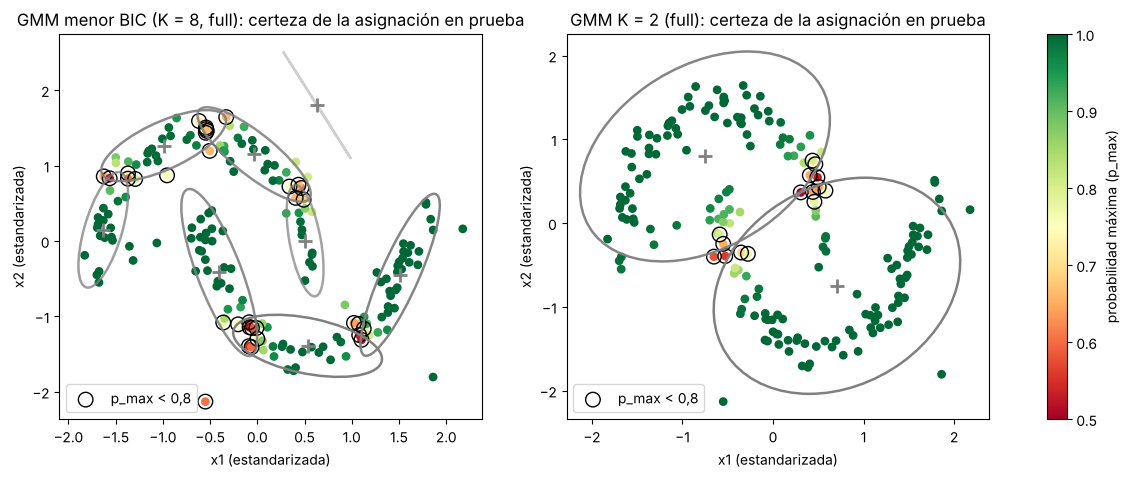

K = 2: 26 puntos de las lunas mal asignados; 19 de ellos con p_max ≥ 0,8 y 7 con p_max < 0,8


In [18]:
res_gmm = {}
for nombre, g in candidatos.items():
    lt = g.predict(Xs_te)
    P = g.predict_proba(Xs_te)
    p_max = P.max(axis=1)
    res_gmm[nombre] = {'lab_te': lt, 'p_max': p_max}
    print(f'{nombre}: componentes usadas en la prueba = {len(set(lt))} | p_max media = {p_max.mean():.3f} '
          f'| puntos con p_max < 0,8: {(p_max < 0.8).sum()} de {len(lt)} ({np.mean(p_max < 0.8):.1%})')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, (nombre, g) in zip(ax, candidatos.items()):
    pm = res_gmm[nombre]['p_max']
    s_ = a.scatter(Xs_te[:, 0], Xs_te[:, 1], c=pm, cmap='RdYlGn', vmin=0.5, vmax=1, s=28)
    a.scatter(Xs_te[pm < 0.8, 0], Xs_te[pm < 0.8, 1], facecolors='none', edgecolors='black', s=110, label='p_max < 0,8')
    dibujar_elipses(a, g, color='grey')
    a.set_title(f'{nombre}: certeza de la asignación en prueba'); a.legend(loc='lower left')
    a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)')
plt.colorbar(s_, ax=ax, label='probabilidad máxima (p_max)'); plt.show()

# Verificación (la etiqueta solo se usa para contar): ¿los errores de K = 2 se cometen con duda o con certeza?
r2 = res_gmm['GMM K = 2 (full)']; luna = y_te_ref != -1
luna_de_comp = pd.crosstab(y_te_ref[luna], r2['lab_te'][luna]).values.argmax(axis=0)   # luna mayoritaria de cada componente
error = luna & (luna_de_comp[r2['lab_te']] != y_te_ref)
print(f"K = 2: {error.sum()} puntos de las lunas mal asignados; {(error & (r2['p_max'] >= 0.8)).sum()} de ellos con p_max ≥ 0,8 "
      f"y {(error & (r2['p_max'] < 0.8)).sum()} con p_max < 0,8")

**Interpretación.**

- **K = 2:** 15 de 186 puntos (8,1 %) tienen p_max < 0,8, con p_max media de 0,959. Los puntos inciertos se concentran donde la punta de cada luna entra en la elipse de la otra. Pero de los 26 puntos de las lunas mal asignados (12 + 14; ver B.8), **19 tienen p_max ≥ 0,8** y solo 7 quedan entre los inciertos: la mayoría de los errores se cometen con certeza alta. Las probabilidades del GMM solo son confiables si su supuesto se cumple, y aquí las lunas no son elipses.
- **K = 8:** 33 puntos (17,7 %) tienen p_max < 0,8, con media 0,919. Hay más duda porque hay más fronteras, pero casi toda es **artificial**: duda entre dos tramos consecutivos de la misma luna, no entre las dos lunas.

## B.7 Detección de anomalías con la log-verosimilitud

`score_samples()` devuelve el logaritmo de la densidad de la mezcla en cada punto. El umbral es el percentil 4 de esa log-densidad en el entrenamiento.

=== GMM menor BIC (K = 8, full) | umbral (percentil 4 de la log-verosimilitud en train) = -3.565
   Prueba        : {'atípicos reales': 8, 'detectados': 6, 'falsas alarmas': 4, 'precisión': 0.6, 'exhaustividad': 0.75}
   Entrenamiento : {'atípicos reales': 12, 'detectados': 6, 'falsas alarmas': 12, 'precisión': 0.333, 'exhaustividad': 0.5}
   Etiqueta real de los puntos marcados en prueba: {-1: 6, 1: 3, 0: 1}
=== GMM K = 2 (full) | umbral (percentil 4 de la log-verosimilitud en train) = -3.620
   Prueba        : {'atípicos reales': 8, 'detectados': 3, 'falsas alarmas': 7, 'precisión': 0.3, 'exhaustividad': 0.375}
   Entrenamiento : {'atípicos reales': 12, 'detectados': 6, 'falsas alarmas': 12, 'precisión': 0.333, 'exhaustividad': 0.5}
   Etiqueta real de los puntos marcados en prueba: {1: 4, 0: 3, -1: 3}

Componente 0 del modelo de menor BIC: peso 0.461%, 2 puntos de entrenamiento, etiquetas reales: [-1, -1] | su log-densidad: [0.11, 0.11]
Valores propios de su covarianza: [0.0, 0.1582

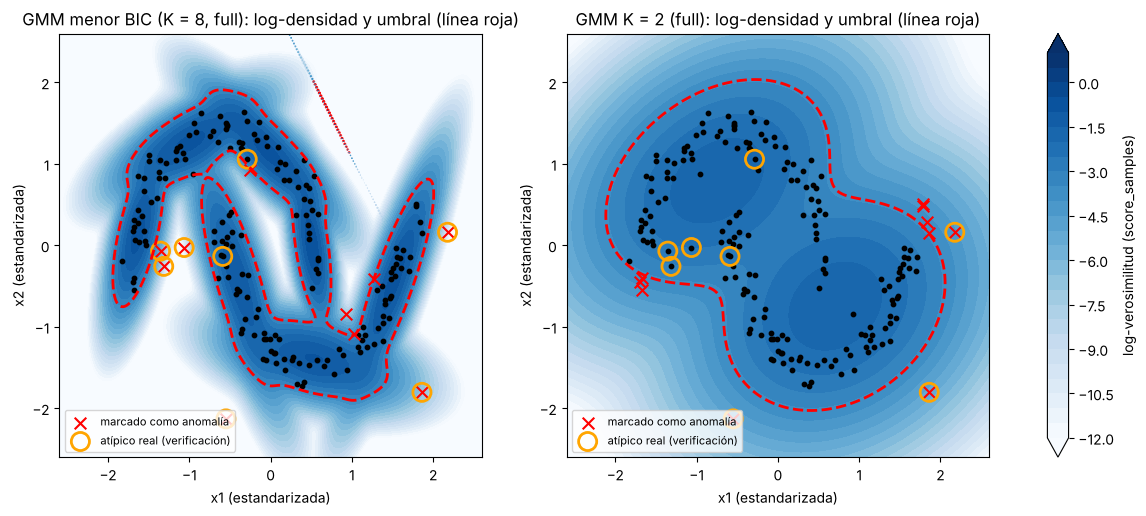

In [19]:
for nombre, g in candidatos.items():
    s_tr = g.score_samples(Xs_tr)                 # log-densidad de cada punto
    umbral = np.percentile(s_tr, 4)               # percentil 4 del entrenamiento
    s_te = g.score_samples(Xs_te)
    anom = s_te < umbral
    res_gmm[nombre].update({'umbral': umbral, 's_te': s_te, 'anom': anom})
    print(f'=== {nombre} | umbral (percentil 4 de la log-verosimilitud en train) = {umbral:.3f}')
    print('   Prueba        :', resumen_anomalias(y_te_ref, anom))
    print('   Entrenamiento :', resumen_anomalias(y_tr_ref, s_tr < umbral))
    print('   Etiqueta real de los puntos marcados en prueba:', pd.Series(y_te_ref[anom]).value_counts().to_dict())

# Una componente "atrapa-atípicos": la de menor peso en el modelo de menor BIC
k_min = int(np.argmin(g_bic.weights_))
pts = Xs_tr[g_bic.predict(Xs_tr) == k_min]
print(f'\nComponente {k_min} del modelo de menor BIC: peso {g_bic.weights_[k_min]:.3%}, {len(pts)} puntos de entrenamiento,',
      'etiquetas reales:', y_tr_ref[g_bic.predict(Xs_tr) == k_min].tolist(),
      '| su log-densidad:', g_bic.score_samples(pts).round(2).tolist())
print('Valores propios de su covarianza:', np.linalg.eigvalsh(cov_componente(g_bic, k_min)).round(5).tolist(),
      '| percentil de esa log-densidad dentro del entrenamiento:', round(100 * np.mean(g_bic.score_samples(Xs_tr) < g_bic.score_samples(pts).min()), 1))

xx, yy = np.meshgrid(np.linspace(-2.6, 2.6, 300), np.linspace(-2.6, 2.6, 300))
malla = np.c_[xx.ravel(), yy.ravel()]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, (nombre, g) in zip(ax, candidatos.items()):
    r = res_gmm[nombre]
    cf = a.contourf(xx, yy, g.score_samples(malla).reshape(xx.shape), levels=np.linspace(-12, 1, 27), cmap='Blues', extend='both')
    a.contour(xx, yy, g.score_samples(malla).reshape(xx.shape), levels=[r['umbral']], colors='red', linewidths=2)
    a.scatter(Xs_te[~r['anom'], 0], Xs_te[~r['anom'], 1], c='black', s=10)
    a.scatter(Xs_te[r['anom'], 0], Xs_te[r['anom'], 1], c='red', marker='x', s=70, label='marcado como anomalía')
    a.scatter(Xs_te[atip_real, 0], Xs_te[atip_real, 1], facecolors='none', edgecolors='orange', s=170, lw=2, label='atípico real (verificación)')
    a.set_title(f'{nombre}: log-densidad y umbral (línea roja)'); a.legend(loc='lower left', fontsize=8)
    a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)')
plt.colorbar(cf, ax=ax, label='log-verosimilitud (score_samples)'); plt.show()

**Interpretación.**

- **K = 8:** umbral −3,565. En la prueba detecta **6 de 8 atípicos con 4 falsas alarmas** (precisión 0,60; exhaustividad 0,75). Su densidad sigue a las lunas muy de cerca: el contorno rojo envuelve cada luna, así que los puntos del hueco y los de fuera de los arcos quedan por debajo del umbral. Las 4 falsas alarmas (3 de la luna 1 y 1 de la luna 0) son puntos en tramos menos densos de las lunas.
- **La componente «atrapa-atípicos»:** la componente 0 (peso 0,46 %) es una elipse **degenerada**: sus valores propios son 0,0 y 0,158, es decir, una línea. Contiene exactamente 2 atípicos de entrenamiento, y la log-densidad de ambos (0,11) está en el **percentil 99,5** del entrenamiento. El modelo «aprendió» esos dos atípicos como lo más normal del dataset, y un atípico nuevo cerca de esa línea pasaría inadvertido. Es el riesgo de las singularidades de la máxima verosimilitud con muchas componentes (Bishop, 2006). Se mitiga con un `reg_covar` mayor, un peso mínimo por componente o un prior bayesiano.
- **K = 2:** umbral −3,620. Detecta solo **3 de 8 con 7 falsas alarmas** (precisión 0,30; exhaustividad 0,375). Sus dos elipses grandes cubren también el hueco entre las lunas, donde la densidad estimada es alta, así que los atípicos del hueco parecen normales. En cambio, las puntas de las lunas, lejos de las medias, quedan con densidad baja y producen las falsas alarmas.
- **Efecto del umbral:** el percentil 4 marca por construcción alrededor del 4 % del entrenamiento (18 puntos), haya o no tantos atípicos. Por eso en entrenamiento ambos modelos tienen 12 falsas alarmas. La precisión depende tanto del modelo como de esa elección.

## B.8 Métricas del modelo

In [20]:
def metricas_gmm(nombre, g):
    r = res_gmm[nombre]; lt = r['lab_te']
    lt_anom = lt.copy(); lt_anom[r['anom']] = -1    # versión comparable con DBSCAN: anomalías como -1
    an = resumen_anomalias(y_te_ref, r['anom'])
    return {'Modelo': nombre, 'K': g.n_components, 'Covarianza': g.covariance_type, 'BIC': round(g.bic(Xs_tr), 1),
            'AIC': round(g.aic(Xs_tr), 1), 'Grupos usados (test)': len(set(lt)),
            'Silueta test': round(silhouette_score(Xs_te, lt), 3), 'DB test': round(davies_bouldin_score(Xs_te, lt), 3),
            'CH test': round(calinski_harabasz_score(Xs_te, lt), 1),
            'ARI test': round(adjusted_rand_score(y_te_ref, lt), 3), 'NMI test': round(normalized_mutual_info_score(y_te_ref, lt), 3),
            'ARI test (anomalías = −1)': round(adjusted_rand_score(y_te_ref, lt_anom), 3),
            'p_max < 0,8': int((r['p_max'] < 0.8).sum()),
            'Anomalías (aciertos / falsas)': f"{an['detectados']} / {an['falsas alarmas']}"}

indicadores_m2 = pd.DataFrame([metricas_gmm(n, g) for n, g in candidatos.items()]).set_index('Modelo')
display(indicadores_m2)
for nombre in candidatos:
    print(f'\n{nombre}: componentes frente a la etiqueta real (prueba)')
    print(pd.crosstab(y_te_ref, res_gmm[nombre]['lab_te'], rownames=['real'], colnames=['componente']))

,K,Covarianza,BIC,AIC,Grupos usados (test),Silueta test,DB test,CH test,ARI test,NMI test,ARI test (anomalías = −1),"p_max < 0,8",Anomalías (aciertos / falsas)
Modelo,,,,,,,,,,,,,
"GMM menor BIC (K = 8, full)",8,full,1782.4,1590.9,7,0.426,0.694,235.7,0.287,0.492,0.290,33,6 / 4
GMM K = 2 (full),2,full,2294.0,2249.2,2,0.481,0.831,241.0,0.456,0.348,0.432,15,3 / 7



GMM menor BIC (K = 8, full): componentes frente a la etiqueta real (prueba)
componente   1   2   3   4   5   6   7
real                                  
-1           0   0   2   1   2   2   1
 0          14  28   0   0  19   0  24
 1           0   0  31  34   0  28   0

GMM K = 2 (full): componentes frente a la etiqueta real (prueba)
componente   0   1
real              
-1           5   3
 0          73  12
 1          14  79


**Interpretación.**

- **K = 2:** ARI 0,456 y NMI 0,348, el **mismo ARI que K-Means con k = 2**. Dos elipses separan las lunas con una frontera casi recta (B.9), igual que un método de centroides. La tabla cruzada lo confirma: 12 puntos de la luna 0 y 14 de la luna 1 quedan en la componente equivocada.
- **K = 8:** ARI 0,287 y NMI 0,492. Usa 7 componentes en la prueba, y cada una es **pura**: las componentes 1, 2, 5 y 7 solo contienen puntos de la luna 0, y las 3, 4 y 6 solo de la luna 1. Por eso el NMI es mayor que con K = 2, pero el ARI castiga haber partido cada luna en 3 o 4 pedazos.
- **Silueta:** 0,481 (K = 2) y 0,426 (K = 8), las dos **mayores que la de DBSCAN (0,384)** aunque recuperan peor las lunas. Es la misma lección de la Parte A y la advertencia de Géron (2019): la silueta premia los trozos convexos. El K = 8 tiene además el menor Davies-Bouldin (0,694).
- Con las anomalías marcadas como −1, el ARI apenas cambia (0,290 y 0,432).

## B.9 Visualización: elipses y fronteras de decisión

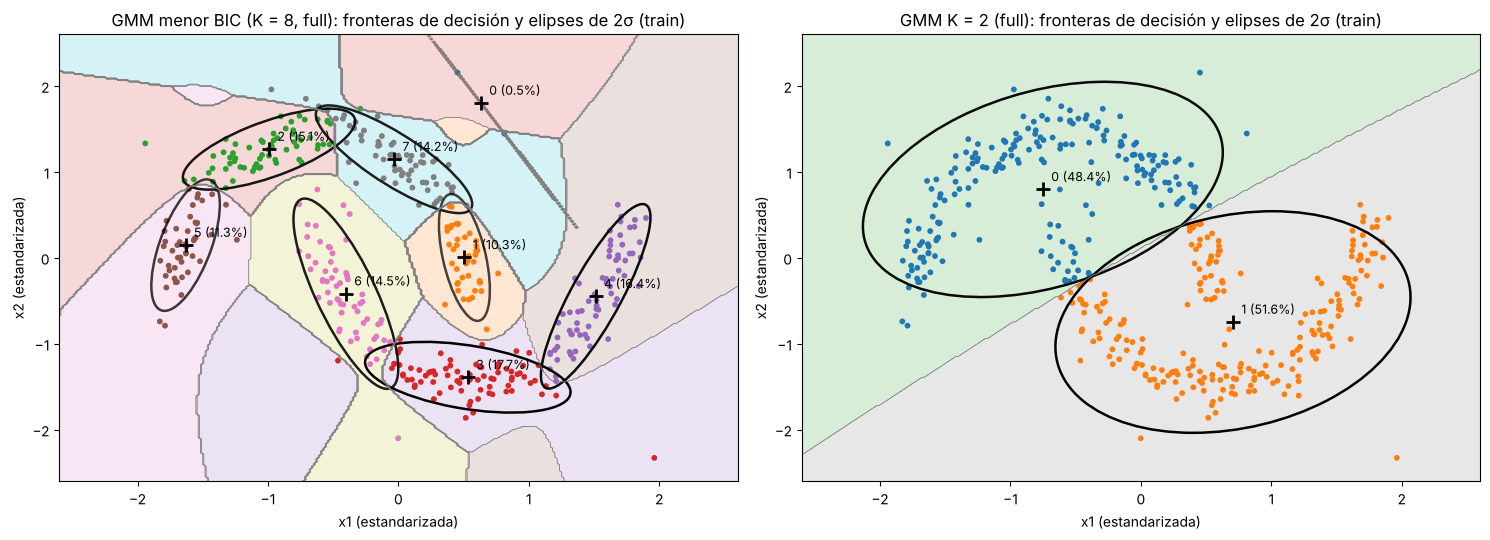

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, (nombre, g) in zip(ax, candidatos.items()):
    zona = g.predict(malla).reshape(xx.shape)
    a.contourf(xx, yy, zona, levels=np.arange(g.n_components + 1) - 0.5, cmap='tab10', alpha=0.18)
    a.contour(xx, yy, zona, levels=np.arange(g.n_components + 1) - 0.5, colors='grey', linewidths=0.6)
    a.scatter(Xs_tr[:, 0], Xs_tr[:, 1], c=g.predict(Xs_tr), cmap='tab10', vmin=0, vmax=9, s=10)
    dibujar_elipses(a, g, color='black', etiquetas=True)
    a.set_xlim(-2.6, 2.6); a.set_ylim(-2.6, 2.6)
    a.set_title(f'{nombre}: fronteras de decisión y elipses de 2σ (train)')
    a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)')
plt.tight_layout(); plt.show()

**Interpretación.**

- **K = 8:** cada luna se aproxima con una **cadena de elipses alargadas** que siguen la curvatura: las componentes 5, 2, 7 y 1 en la luna superior, y 6, 3 y 4 en la inferior. La componente 0 aparece como una línea fina fuera de las lunas. Las fronteras de decisión cortan cada luna de forma transversal.
- **K = 2:** dos elipses grandes, cada una con una luna y su concavidad. La frontera entre ellas es una diagonal casi recta, y las puntas de cada luna quedan del lado equivocado.

### Indicadores del Modelo 2

In [22]:
indicadores_m2[['K', 'Covarianza', 'BIC', 'Silueta test', 'ARI test', 'Anomalías (aciertos / falsas)']]

,K,Covarianza,BIC,Silueta test,ARI test,Anomalías (aciertos / falsas)
Modelo,,,,,,
"GMM menor BIC (K = 8, full)",8,full,1782.4,0.426,0.287,6 / 4
GMM K = 2 (full),2,full,2294.0,0.481,0.456,3 / 7


**Análisis de la pista.** Que el menor BIC use 8 componentes no es un error: el GMM es un **estimador de densidad**, y una componente no es un cluster.

- **Para el clustering**, 8 componentes fragmentan cada luna (ARI 0,287).
- **Para la detección de anomalías**, esas mismas 8 componentes dan una densidad que se ciñe a las lunas. Por eso es el modelo que más atípicos detecta (6 de 8, frente a 3 de 8 con K = 2), aunque la componente degenerada muestra que demasiada flexibilidad también puede «normalizar» atípicos.
- **K = 2 tampoco es la solución:** una componente elíptica no se puede curvar.

La salida natural es **combinar componentes** para formar grupos (Experimento 1 de la Parte C).

# Parte C — Comparación de modelos y análisis crítico

## 7.1 Tabla comparativa en las medias lunas

Se incluyen los dos candidatos del GMM. El tiempo es el promedio de 20 ajustes medidos con `time.perf_counter()`; varía según el equipo, pero el orden de magnitud se mantiene.

In [23]:
def tiempo_medio_ms(fn, rep=20):
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return np.mean(ts) * 1000

t_db = tiempo_medio_ms(lambda: DBSCAN(eps=0.25, min_samples=5).fit(Xs_tr))
t_db_knn = tiempo_medio_ms(lambda: asignar_prueba(dbscan, lab_tr, Xs_te, 0.25))
t_g2 = tiempo_medio_ms(lambda: GaussianMixture(2, covariance_type='full', n_init=5, random_state=42).fit(Xs_tr))
t_g8 = tiempo_medio_ms(lambda: GaussianMixture(g_bic.n_components, covariance_type=g_bic.covariance_type, n_init=5, random_state=42).fit(Xs_tr))
print(f'DBSCAN: {t_db:.2f} ms (+ {t_db_knn:.2f} ms para asignar la prueba) | GMM K=2: {t_g2:.2f} ms | '
      f'GMM K={g_bic.n_components}: {t_g8:.2f} ms | grilla de 32 GMM: {t_grilla:.2f} s')

m_db = metricas(Xs_te, lab_te); an_db = resumen_anomalias(y_te_ref, lab_te == -1)
def col_gmm(nombre, g, t):
    fila = indicadores_m2.loc[nombre]; an = resumen_anomalias(y_te_ref, res_gmm[nombre]['anom'])
    return [f"{g.n_components} componentes ({fila['Grupos usados (test)']} usadas en prueba)",
            f"{fila['ARI test']:.3f} / {fila['NMI test']:.3f}",
            f"{fila['Silueta test']:.3f} (no hay ruido: todos los puntos)",
            f"{an['detectados']} de {an['atípicos reales']} / {an['falsas alarmas']} (con score_samples, percentil 4)",
            'Sí: K se fija antes (aquí se eligió con BIC)' if g is g_bic else 'Sí: K = 2 fijado a priori',
            'Sí: predict() nativo', 'Sí: predict_proba() y score_samples()',
            f'{t:.1f} ms (n_init = 5) + {t_grilla:.2f} s de la grilla BIC']
tabla_71 = pd.DataFrame({
    'DBSCAN (eps = 0,25)': [f"{m_db['clusters']} clusters + ruido ({m_db['ruido_%']} % en prueba)",
        f"{adjusted_rand_score(y_te_ref, lab_te):.3f} / {normalized_mutual_info_score(y_te_ref, lab_te):.3f}",
        f"{m_db['silueta']:.3f} (sin ruido)", f"{an_db['detectados']} de {an_db['atípicos reales']} / {an_db['falsas alarmas']}",
        'No: lo deduce de la densidad (fija eps y min_samples)', 'No: necesita un 1-NN sobre los núcleos + umbral eps',
        'No: etiqueta dura (o ruido)', f'{t_db:.1f} ms (+ {t_db_knn:.1f} ms del 1-NN)'],
    'GMM (K = 2, cov = full)': col_gmm('GMM K = 2 (full)', g_2, t_g2),
    f'GMM (K = {g_bic.n_components}, cov = {g_bic.covariance_type}) — menor BIC': col_gmm(list(candidatos)[0], g_bic, t_g8),
}, index=['Número de grupos encontrados', 'ARI / NMI (test)', 'Silueta test', 'Atípicos detectados / falsas alarmas',
          '¿Requiere fijar el número de grupos?', '¿Asigna datos nuevos (predict)?', '¿Entrega probabilidades?',
          'Tiempo de entrenamiento'])
tabla_71

DBSCAN: 1.90 ms (+ 2.22 ms para asignar la prueba) | GMM K=2: 15.52 ms | GMM K=8: 46.73 ms | grilla de 32 GMM: 0.82 s


,"DBSCAN (eps = 0,25)","GMM (K = 2, cov = full)","GMM (K = 8, cov = full) — menor BIC"
Número de grupos encontrados,2 clusters + ruido (2.7 % en prueba),2 componentes (2 usadas en prueba),8 componentes (7 usadas en prueba)
ARI / NMI (test),0.967 / 0.927,0.456 / 0.348,0.287 / 0.492
Silueta test,0.384 (sin ruido),0.481 (no hay ruido: todos los puntos),0.426 (no hay ruido: todos los puntos)
Atípicos detectados / falsas alarmas,5 de 8 / 0,"3 de 8 / 7 (con score_samples, percentil 4)","6 de 8 / 4 (con score_samples, percentil 4)"
¿Requiere fijar el número de grupos?,No: lo deduce de la densidad (fija eps y min_s...,Sí: K = 2 fijado a priori,Sí: K se fija antes (aquí se eligió con BIC)
¿Asigna datos nuevos (predict)?,No: necesita un 1-NN sobre los núcleos + umbra...,Sí: predict() nativo,Sí: predict() nativo
¿Entrega probabilidades?,No: etiqueta dura (o ruido),Sí: predict_proba() y score_samples(),Sí: predict_proba() y score_samples()
Tiempo de entrenamiento,1.9 ms (+ 2.2 ms del 1-NN),15.5 ms (n_init = 5) + 0.82 s de la grilla BIC,46.7 ms (n_init = 5) + 0.82 s de la grilla BIC


**Lectura de la tabla.** En las medias lunas, **DBSCAN gana en lo esencial**: recupera las dos lunas (ARI 0,967 frente a 0,456 y 0,287) y detecta anomalías con mejor precisión (5 de 8 sin falsas alarmas). El GMM gana en **funcionalidad**: tiene `predict()` nativo, entrega probabilidades y da una densidad con la que se puede puntuar cualquier dato nuevo. Además, para usar DBSCAN en producción hay que guardar los 414 puntos núcleo, mientras que el GMM con K = 8 se resume en 47 parámetros. Los tiempos (unos pocos milisegundos para DBSCAN, decenas de milisegundos por GMM con `n_init=5` y menos de 1 s para la grilla BIC) son despreciables a este tamaño. El costo real del GMM está en tener que **buscar K y la covarianza**.

## 7.2 Segundo escenario: grupos elípticos de distinta densidad

Tres grupos elípticos, inclinados y con desviaciones 1,0, 2,5 y 0,5. El código de generación es el de la guía.

**Criterios (sin etiquetas):**

- **DBSCAN:** min_samples = 5 (misma regla, D = 2). Se recorre eps de 0,05 a 0,45 y se consideran **admisibles** los valores con ruido ≤ 10 % y al menos 2 grupos de 30 puntos o más (5 % de los datos, para no contar micro-clusters como grupos). Entre ellos se elige el de mayor silueta sin ruido, y se contrasta con el codo de k-distancias.
- **GMM:** se repite la grilla de BIC para ver qué elegiría sin conocer K, y se ajusta el modelo que pide la guía (K = 3, full).

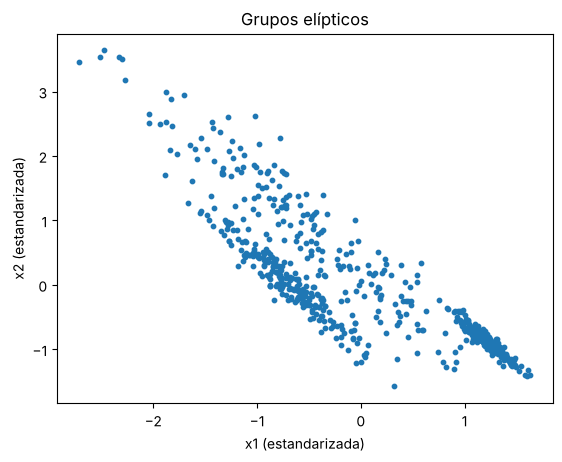

k-distancia (k = 5) -> percentiles 10 / 50 / 90: [0.025 0.066 0.185]
Cociente entre el percentil 90 y el 10 de la k-distancia: 7.4


In [24]:
from sklearn.datasets import make_blobs
Xb, yb = make_blobs(n_samples=600, centers=3, cluster_std=[1.0, 2.5, 0.5], random_state=170)
Xb = Xb @ np.array([[0.6, -0.64], [-0.41, 0.85]])   # estira e inclina los grupos
Xb = StandardScaler().fit_transform(Xb)
plt.scatter(Xb[:, 0], Xb[:, 1], s=10); plt.title('Grupos elípticos')
plt.xlabel('x1 (estandarizada)'); plt.ylabel('x2 (estandarizada)'); plt.show()

# Densidad local de cada punto: la misma k-distancia que usa DBSCAN (k = 5)
kd_b = NearestNeighbors(n_neighbors=5).fit(Xb).kneighbors(Xb)[0][:, -1]
print('k-distancia (k = 5) -> percentiles 10 / 50 / 90:', np.percentile(kd_b, [10, 50, 90]).round(3))
print('Cociente entre el percentil 90 y el 10 de la k-distancia:', round(np.percentile(kd_b, 90) / np.percentile(kd_b, 10), 1))

Codo del gráfico de k-distancias: 0.183 (percentil 90)


,clusters,clusters ≥ 30 pts,ruido %,silueta (sin ruido),tamaños (mayores)
eps,,,,,
0.050,12,1,56.2,0.398,"[167, 12, 12, 12]"
0.075,8,2,40.3,0.467,"[195, 133, 6, 6]"
0.100,11,2,30.5,0.469,"[201, 156, 10, 9]"
0.125,14,2,19.0,0.348,"[202, 190, 14, 13]"
0.150,10,2,12.5,0.326,"[202, 198, 29, 29]"
0.175,4,2,7.0,0.321,"[344, 203, 6, 5]"
0.200,3,2,3.5,0.509,"[364, 210, 5]"
0.225,3,1,2.0,0.458,"[578, 5, 5]"
0.250,3,1,1.8,0.459,"[579, 5, 5]"


eps admisibles (ruido ≤ 10 % y al menos 2 grupos de ≥ 30 puntos): [0.175, 0.2] -> eps elegido: 0.2


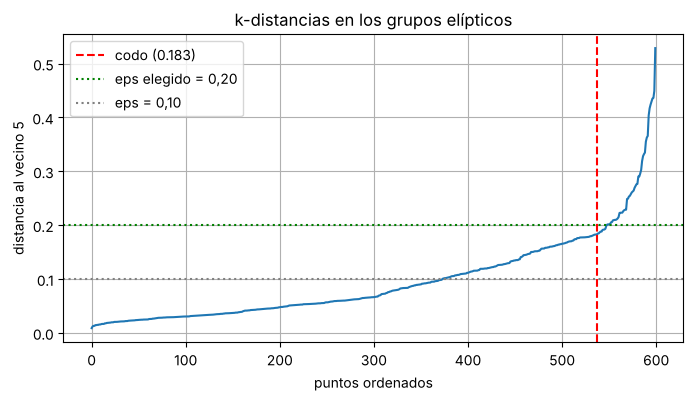

In [25]:
# DBSCAN: k-distancias + barrido de eps con criterios internos
kd_s = np.sort(kd_b)
xn_b = np.arange(len(kd_s)) / (len(kd_s) - 1); yn_b = (kd_s - kd_s[0]) / (kd_s[-1] - kd_s[0])
i_codo_b = int(np.argmax(xn_b - yn_b))
print(f'Codo del gráfico de k-distancias: {kd_s[i_codo_b]:.3f} (percentil {100 * i_codo_b / len(kd_s):.0f})')

TAM_MIN_B = int(0.05 * len(Xb))   # un "grupo" debe tener al menos el 5 % de los puntos
filas_b = []
for e in np.round(np.arange(0.05, 0.451, 0.025), 3):
    l = DBSCAN(eps=e, min_samples=5).fit(Xb).labels_; m = l != -1
    tam = np.bincount(l[m]) if m.any() else np.array([])
    n_cl = len(tam)
    filas_b.append({'eps': e, 'clusters': n_cl, f'clusters ≥ {TAM_MIN_B} pts': int((tam >= TAM_MIN_B).sum()),
                    'ruido %': round(100 * np.mean(~m), 1),
                    'silueta (sin ruido)': round(silhouette_score(Xb[m], l[m]), 3) if n_cl > 1 else np.nan,
                    'tamaños (mayores)': sorted(tam.tolist(), reverse=True)[:4]})
barrido_b = pd.DataFrame(filas_b).set_index('eps')
display(barrido_b)
validos = barrido_b[(barrido_b['ruido %'] <= 10) & (barrido_b[f'clusters ≥ {TAM_MIN_B} pts'] >= 2)]
eps_b = float(validos['silueta (sin ruido)'].idxmax())
eps_b_txt = f'{eps_b:.2f}'.replace('.', ',')
print(f'eps admisibles (ruido ≤ 10 % y al menos 2 grupos de ≥ {TAM_MIN_B} puntos):', validos.index.tolist(), '-> eps elegido:', eps_b)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kd_s); ax.axvline(i_codo_b, color='red', ls='--', label=f'codo ({kd_s[i_codo_b]:.3f})')
ax.axhline(eps_b, color='green', ls=':', label=f'eps elegido = {eps_b_txt}'); ax.axhline(0.10, color='grey', ls=':', label='eps = 0,10')
ax.set_xlabel('puntos ordenados'); ax.set_ylabel('distancia al vecino 5'); ax.set_title('k-distancias en los grupos elípticos')
ax.legend(); ax.grid(); plt.show()

     full    tied    diag  spherical
K                                   
1  2698.4  2698.4  3431.0     3424.6
2  1653.0  2377.8  2394.1     2466.3
3  1345.2  1990.0  2190.8     2206.7
4  1377.4  1835.7  2102.4     2134.5
5  1404.5  1741.4  2055.5     2062.2
6  1427.8  1717.4  1956.5     1956.1
7  1469.8  1722.0  1949.5     1927.7
8  1501.2  1734.8  1924.0     1903.5
Menor BIC: (3, 'full')


,"DBSCAN (eps = 0,20)","DBSCAN (eps = 0,10, referencia)","GMM (K = 3, full)"
Número de grupos encontrados,3,11,3
% de puntos marcados como ruido,3.5 %,30.5 %,0 % (no tiene ruido)
ARI / NMI,0.539 / 0.630,0.714 / 0.696,0.956 / 0.935
Silueta,0.509 (sin ruido),0.469 (sin ruido),0.403
Davies-Bouldin,0.431,0.459,1.473


GMM K = 3 -> pesos: [0.332 0.342 0.326] | p_max < 0,8: 9 puntos

Verificación con la etiqueta real (filas) — DBSCAN eps = 0,20:
dbscan  -1    0    1   2
real                    
0        1  199    0   0
1       20  165   10   5
2        0    0  200   0

GMM K = 3:
gmm     0    1    2
real               
0       0  199    1
1       1    7  192
2     200    0    0

k-distancia mediana dentro de cada grupo real: {0: 0.065, 1: 0.16, 2: 0.031}


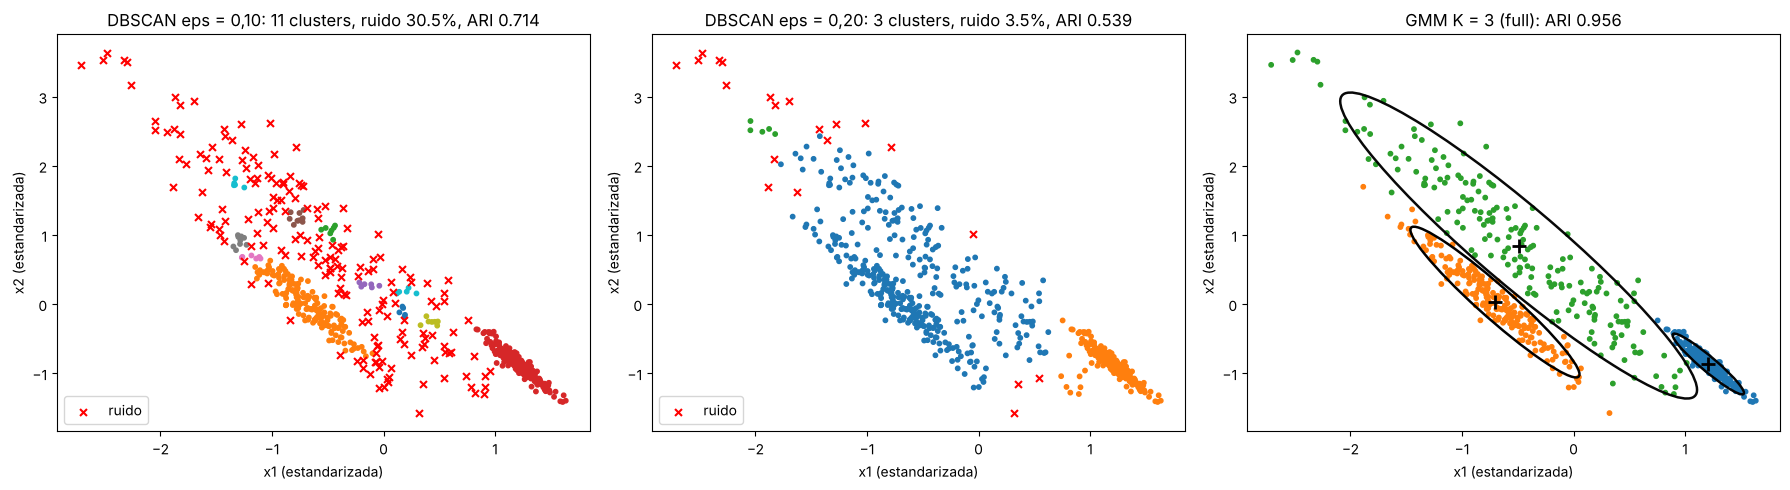

In [26]:
# GMM: selección por BIC (sin etiquetas) y modelo pedido por la guía (K = 3, full)
bic_b = pd.DataFrame({cov: [GaussianMixture(K, covariance_type=cov, n_init=5, random_state=42).fit(Xb).bic(Xb) for K in range(1, 9)]
                      for cov in TIPOS_COV}, index=range(1, 9)).round(1)
bic_b.index.name = 'K'
print(bic_b)
print('Menor BIC:', bic_b.stack().idxmin())

g_b = GaussianMixture(3, covariance_type='full', n_init=5, random_state=42).fit(Xb)
lab_gb = g_b.predict(Xb); pmax_b = g_b.predict_proba(Xb).max(axis=1)
lab_db_b = DBSCAN(eps=eps_b, min_samples=5).fit(Xb).labels_
lab_db_b10 = DBSCAN(eps=0.10, min_samples=5).fit(Xb).labels_

def fila_esc2(lab, ruido=True):
    m = lab != -1
    return {'Número de grupos encontrados': len(set(lab[m])),
            '% de puntos marcados como ruido': f'{100 * np.mean(~m):.1f} %' if ruido else '0 % (no tiene ruido)',
            'ARI / NMI': f'{adjusted_rand_score(yb, lab):.3f} / {normalized_mutual_info_score(yb, lab):.3f}',
            'Silueta': f'{silhouette_score(Xb[m], lab[m]):.3f}' + (' (sin ruido)' if ruido else ''),
            'Davies-Bouldin': f'{davies_bouldin_score(Xb[m], lab[m]):.3f}'}
tabla_72 = pd.DataFrame({f'DBSCAN (eps = {eps_b_txt})': fila_esc2(lab_db_b),
                         'DBSCAN (eps = 0,10, referencia)': fila_esc2(lab_db_b10),
                         'GMM (K = 3, full)': fila_esc2(lab_gb, ruido=False)})
display(tabla_72)
print('GMM K = 3 -> pesos:', g_b.weights_.round(3), '| p_max < 0,8:', int((pmax_b < 0.8).sum()), 'puntos')
print(f'\nVerificación con la etiqueta real (filas) — DBSCAN eps = {eps_b_txt}:')
print(pd.crosstab(yb, lab_db_b, rownames=['real'], colnames=['dbscan']))
print('\nGMM K = 3:')
print(pd.crosstab(yb, lab_gb, rownames=['real'], colnames=['gmm']))
print('\nk-distancia mediana dentro de cada grupo real:', {int(c): round(float(np.median(kd_b[yb == c])), 3) for c in range(3)})

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, lab, tit in [(ax[0], lab_db_b10, 'DBSCAN eps = 0,10'), (ax[1], lab_db_b, f'DBSCAN eps = {eps_b_txt}')]:
    a.scatter(Xb[lab != -1, 0], Xb[lab != -1, 1], c=lab[lab != -1], cmap='tab10', vmin=0, vmax=9, s=10)
    a.scatter(Xb[lab == -1, 0], Xb[lab == -1, 1], c='red', marker='x', s=25, label='ruido')
    a.set_title(f'{tit}: {len(set(lab[lab != -1]))} clusters, ruido {np.mean(lab == -1):.1%}, ARI {adjusted_rand_score(yb, lab):.3f}'); a.legend(loc='lower left')
ax[2].scatter(Xb[:, 0], Xb[:, 1], c=lab_gb, cmap='tab10', vmin=0, vmax=9, s=10); dibujar_elipses(ax[2], g_b)
ax[2].set_title(f'GMM K = 3 (full): ARI {adjusted_rand_score(yb, lab_gb):.3f}')
for a in ax: a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)')
plt.tight_layout(); plt.show()

**Interpretación.**

- **Densidades muy distintas:** la k-distancia va de 0,025 (percentil 10) a 0,185 (percentil 90), 7,4 veces más. La mediana dentro de cada grupo real es 0,031 (denso), 0,065 (medio) y 0,160 (disperso): el grupo disperso necesita un radio **5 veces mayor** que el denso.
- **DBSCAN:** el codo está en 0,183. Los eps admisibles son 0,175 y 0,20, y se elige **eps = 0,20** (silueta 0,509): 3 clusters (364, 210 y 5 puntos) y 3,5 % de ruido.
  - **Verificación:** ARI 0,539 y NMI 0,630. Recupera el grupo denso (200 de 200), pero **fusiona** el grupo medio (199 puntos) con 165 puntos del disperso. Un radio suficiente para conectar el grupo disperso también tiende un puente hacia el grupo medio, que está al lado.
  - **Con eps = 0,10 (referencia):** separa los dos grupos compactos, pero el disperso **se disuelve**: 151 de sus 200 puntos pasan a ruido y el resto forma micro-clusters (11 clusters en total, 30,5 % de ruido, ARI 0,714).
- **GMM:** la grilla elige **K = 3 con covarianza full** (BIC 1345,2) sin usar etiquetas, que es el número real de grupos. Con ese modelo, ARI = **0,956** y NMI = 0,935, solo 9 puntos con p_max < 0,8 y pesos ≈ 1/3 cada uno. Los 9 errores están donde las elipses se solapan de verdad: 7 puntos del grupo disperso asignados al medio, 1 asignado al denso y 1 del grupo medio asignado al disperso.
- **Las métricas internas vuelven a engañar:** DBSCAN con eps = 0,20 tiene mayor silueta (0,509) y menor Davies-Bouldin (0,431) que el GMM (0,403 y 1,473), aunque su partición es mucho peor. Un cluster grande fusionado junto a otro muy compacto *parece* bien separado.

## 7.3 Preguntas de análisis

**1. ¿Qué modelo funcionó mejor en las medias lunas y cuál en los grupos elípticos? Explique la diferencia a partir de los supuestos de cada algoritmo.**

- **Medias lunas: DBSCAN** (ARI 0,967 frente a 0,456 del GMM con K = 2 y 0,287 con K = 8). DBSCAN solo supone que un grupo es una región **conectada de densidad suficiente**, sin importar su forma: la cadena de núcleos sigue cada arco. El GMM supone que cada grupo es una **elipse gaussiana**. Con K = 2 no puede curvarse, y con K = 8 describe bien la densidad, pero cada luna queda partida en varias componentes.
- **Grupos elípticos: GMM** (ARI 0,956 frente a 0,539 de DBSCAN). Aquí los datos cumplen exactamente el supuesto del GMM: cada grupo es una gaussiana con su propia covarianza (inclinada y de distinto tamaño). En cambio, rompen el supuesto implícito de DBSCAN de que **una sola densidad** (un solo eps) define todos los grupos.

**2. En los grupos elípticos, ¿por qué no existe un único eps que funcione bien para DBSCAN?**

Porque eps fija **un solo umbral de densidad** para todo el espacio, y los tres grupos tienen densidades distintas. La k-distancia mediana es 0,031 en el grupo denso, 0,065 en el medio y 0,160 en el disperso.

- **eps pequeño (0,10):** sirve a los grupos compactos, pero los puntos del grupo disperso no alcanzan 5 vecinos y pasan a ruido (151 de 200).
- **eps grande (0,20):** conecta el grupo disperso, pero también el espacio entre grupos vecinos, y el medio y el disperso se fusionan (364 puntos en un cluster).

El barrido muestra que **ningún** eps entre 0,05 y 0,45 da 3 grupos de tamaño razonable con poco ruido: o se fragmenta y se pierde el grupo disperso, o se fusiona.

**3. ¿Qué ventaja práctica tiene `predict_proba()` del GMM frente a la etiqueta dura de DBSCAN? Dé un ejemplo de negocio.**

`predict_proba()` dice **cuánta confianza** hay en cada asignación. Así se puede actuar distinto según la certeza: automatizar los casos claros y revisar los dudosos, ponderar decisiones por probabilidad o cuantificar el riesgo de error. DBSCAN solo entrega «grupo A», «grupo B» o «ruido».

*Ejemplo de negocio:* una cadena de supermercados segmenta clientes para campañas. Un cliente con probabilidades 0,55 «sensible al precio» y 0,45 «compra premium» no debería recibir una sola campaña rígida: se le puede enviar una oferta mixta o dejarlo en el grupo de prueba A/B. Los clientes con p_max > 0,9 reciben la campaña de su segmento de forma automática. En este trabajo, 15 puntos de prueba (8,1 %) con p_max < 0,8 serían los «casos a revisar».

Matiz importante (B.6): las probabilidades solo son confiables si el modelo es adecuado. Con K = 2 en las lunas, 19 de los 26 errores se cometieron con p_max ≥ 0,8.

**4. Compare la detección de anomalías: ruido de DBSCAN vs. baja log-verosimilitud del GMM. ¿Cuál detectó más atípicos reales? ¿Cuál tuvo más falsas alarmas?**

| Prueba (8 atípicos reales) | Detectados | Falsas alarmas | Precisión | Exhaustividad |
|---|---|---|---|---|
| DBSCAN (eps = 0,25) | 5 | **0** | **1,00** | 0,625 |
| GMM K = 8 (menor BIC) | **6** | 4 | 0,60 | **0,75** |
| GMM K = 2 (full) | 3 | **7** | 0,30 | 0,375 |

- **Más atípicos detectados:** el GMM con K = 8 (6 de 8), porque su densidad se ciñe a las lunas.
- **Más falsas alarmas:** el GMM con K = 2 (7). Sus elipses cubren el hueco entre las lunas y dejan las puntas con densidad baja.
- **DBSCAN** es el más **preciso** (ninguna falsa alarma). Su criterio de ruido se adapta a la densidad local, mientras que el umbral del percentil 4 obliga al GMM a marcar alrededor de un 4 % de los puntos aunque no sean atípicos.

Los 2 o 3 atípicos que ningún método detecta cayeron pegados a una luna y no se pueden distinguir por densidad.

## 7.4 ¿Cuándo funcionaría mejor el GMM? ¿Qué faltó?

Para sostener la conclusión se realizan cuatro experimentos sin usar etiquetas en las decisiones: fusión de componentes, GMM bayesiano, transformación de variables y HDBSCAN.

### Experimento 1 — Usar más componentes y fusionarlas después

Se parte del modelo de menor BIC (K = 8, que describe bien la densidad) y se fusionan sus componentes de a pares. En cada paso se elige la fusión que **más reduce la entropía** de las probabilidades de pertenencia (Baudry et al., 2010). Fusionar dos componentes que se solapan mucho reduce mucho la entropía; fusionar dos que están bien separadas casi no la reduce. Por eso se detiene la fusión donde la reducción cae bruscamente.

,entropía,composición,reducción al llegar aquí
grupos,,,
8,57.76,"[[0], [1], [2], [3], [4], [5], [6], [7]]",NaN
7,42.88,"[[0], [1], [2, 7], [3], [4], [5], [6]]",14.88
6,28.88,"[[0], [1], [2, 7], [3, 6], [4], [5]]",14.00
5,19.69,"[[0], [1, 2, 7], [3, 6], [4], [5]]",9.19
4,10.74,"[[0], [1, 2, 7, 5], [3, 6], [4]]",8.95
3,2.64,"[[0], [1, 2, 7, 5], [3, 6, 4]]",8.10
2,0.00,"[[0], [1, 2, 7, 5, 3, 6, 4]]",2.64


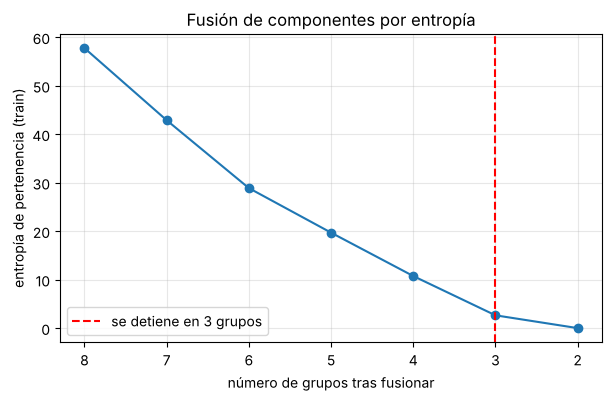

In [27]:
def entropia(T):
    T = np.clip(T, 1e-300, 1)
    return -(T * np.log(T)).sum()

def fusionar_por_entropia(T):
    """Fusiona componentes de a pares eligiendo siempre la fusión que más reduce la entropía de las
    probabilidades de pertenencia (Baudry et al., 2010). Devuelve la historia de fusiones."""
    grupos = [[k] for k in range(T.shape[1])]; T = T.copy()
    historia = [(len(grupos), entropia(T), [g[:] for g in grupos])]
    while T.shape[1] > 2:   # se fusiona hasta llegar a 2 grupos
        mejor = None
        for a in range(T.shape[1]):
            for b in range(a + 1, T.shape[1]):
                reduccion = entropia(T[:, [a]]) + entropia(T[:, [b]]) - entropia(T[:, [a]] + T[:, [b]])
                if mejor is None or reduccion > mejor[0]:
                    mejor = (reduccion, a, b)
        _, a, b = mejor
        T[:, a] += T[:, b]; T = np.delete(T, b, axis=1)
        grupos[a] += grupos[b]; del grupos[b]
        historia.append((len(grupos), entropia(T), [g[:] for g in grupos]))
    return historia

historia = fusionar_por_entropia(g_bic.predict_proba(Xs_tr))
hist_df = pd.DataFrame([{'grupos': n, 'entropía': round(e, 2), 'composición': str(gr)} for n, e, gr in historia]).set_index('grupos')
hist_df['reducción al llegar aquí'] = (hist_df['entropía'].shift(1) - hist_df['entropía']).round(2)
display(hist_df)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist_df.index, hist_df['entropía'], 'o-'); ax.invert_xaxis()
ax.axvline(3, color='red', ls='--', label='se detiene en 3 grupos')
ax.set_xlabel('número de grupos tras fusionar'); ax.set_ylabel('entropía de pertenencia (train)')
ax.set_title('Fusión de componentes por entropía'); ax.legend(); ax.grid(alpha=0.3); plt.show()

Grupos tras fusionar: [[0], [1, 2, 7, 5], [3, 6, 4]] | pesos: [0.005 0.509 0.486]
{'Modelo': 'GMM K = 8 fusionado en 2 grupos', 'Grupos (test)': 2, 'ARI test': 0.915, 'NMI test': 0.866, 'ARI test (anomalías = −1)': 0.933, 'Silueta test (sin anomalías)': 0.38, 'p_max < 0,8': 1}
fusión + anomalías  -1   1   2
real                          
-1                   6   1   1
 0                   1  84   0
 1                   3   0  90
ARI en entrenamiento (fusión): 0.954


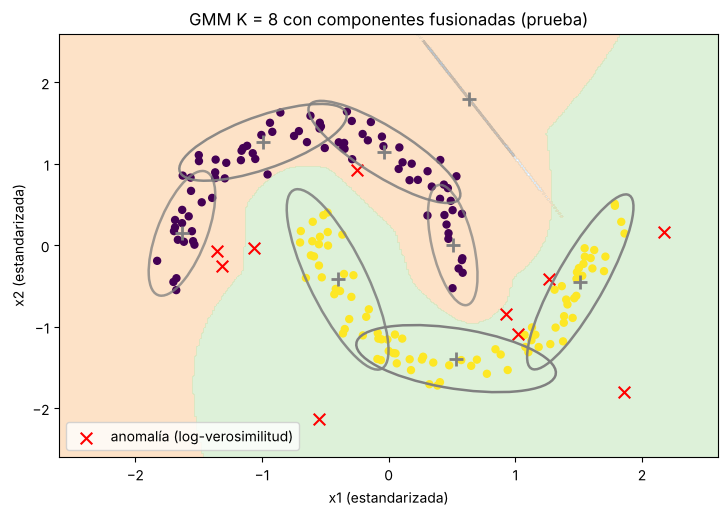

In [28]:
# Se detiene donde la reducción de entropía cae bruscamente (3 grupos) y los grupos con peso < 2 % se tratan como componentes de ruido
grupos_f = [g for n, e, g in historia if n == 3][0]
pesos_f = np.array([g_bic.weights_[g].sum() for g in grupos_f])
print('Grupos tras fusionar:', grupos_f, '| pesos:', pesos_f.round(3))
es_ruido_f = pesos_f < 0.02

def predecir_fusion(Xs):
    P = g_bic.predict_proba(Xs)
    Pf = np.column_stack([P[:, g].sum(axis=1) for g in grupos_f])
    lab = Pf.argmax(axis=1); lab[es_ruido_f[lab]] = -1
    return lab, Pf.max(axis=1)

lab_f_te, pmax_f = predecir_fusion(Xs_te)
lab_f_comb = lab_f_te.copy(); lab_f_comb[res_gmm[list(candidatos)[0]]['anom']] = -1   # + anomalías por log-verosimilitud
mf = lab_f_comb != -1
fila_fusion = {'Modelo': f'GMM K = {g_bic.n_components} fusionado en 2 grupos', 'Grupos (test)': len(set(lab_f_te[lab_f_te != -1])),
               'ARI test': round(adjusted_rand_score(y_te_ref, lab_f_te), 3), 'NMI test': round(normalized_mutual_info_score(y_te_ref, lab_f_te), 3),
               'ARI test (anomalías = −1)': round(adjusted_rand_score(y_te_ref, lab_f_comb), 3),
               'Silueta test (sin anomalías)': round(silhouette_score(Xs_te[mf], lab_f_comb[mf]), 3),
               'p_max < 0,8': int((pmax_f < 0.8).sum())}
print(fila_fusion)
print(pd.crosstab(y_te_ref, lab_f_comb, rownames=['real'], colnames=['fusión + anomalías']))
lab_f_tr, _ = predecir_fusion(Xs_tr)
print('ARI en entrenamiento (fusión):', round(adjusted_rand_score(y_tr_ref, lab_f_tr), 3))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
zona = predecir_fusion(malla)[0].reshape(xx.shape)
ax.contourf(xx, yy, zona, levels=[-1.5, -0.5, 0.5, 1.5, 2.5], colors=['white', '#c6dbef', '#fdd0a2', '#c7e9c0'], alpha=0.6)
ax.scatter(Xs_te[mf, 0], Xs_te[mf, 1], c=lab_f_comb[mf], cmap='viridis', s=25)
ax.scatter(Xs_te[~mf, 0], Xs_te[~mf, 1], c='red', marker='x', s=70, label='anomalía (log-verosimilitud)')
dibujar_elipses(ax, g_bic, color='grey')
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6); ax.legend(loc='lower left')
ax.set_xlabel('x1 (estandarizada)'); ax.set_ylabel('x2 (estandarizada)')
ax.set_title(f'GMM K = {g_bic.n_components} con componentes fusionadas (prueba)'); plt.show()

**Resultado.**

- **Dónde parar:** las reducciones de entropía son 14,88, 14,00, 9,19, 8,95 y 8,10, y la última fusión solo reduce **2,64**. Se detiene en **3 grupos**: {1, 2, 5, 7} (peso 50,9 %), {3, 4, 6} (48,6 %) y {0} (0,5 %). El grupo {0} es la componente degenerada de 2 puntos: con peso menor al 2 % no es un grupo, así que sus puntos se tratan como ruido. La última fusión, la que se descartó, habría unido las dos lunas, y su reducción pequeña indica justamente que están bien separadas.
- **En la prueba:** ARI **0,915** (NMI 0,866) y **solo 1 punto con p_max < 0,8** (frente a 15 con K = 2). Las dos lunas quedan separadas sin errores entre ellas. Si se agregan las anomalías por log-verosimilitud, el ARI sube a **0,933**, cerca del 0,967 de DBSCAN. En entrenamiento, el ARI es 0,954.
- Este es el principal «qué faltó» del GMM: las componentes eran el material correcto, pero faltaba un paso que convierta componentes en grupos. El modelo final conserva las ventajas del GMM (`predict`, probabilidades y densidad) y separa las lunas casi tan bien como DBSCAN.

In [29]:
# Experimento 2: GMM bayesiano con proceso de Dirichlet (puede "apagar" componentes sobrantes)
filas_bg = []
for prior in [1.0, 0.01, 0.001]:
    bg = BayesianGaussianMixture(n_components=10, covariance_type='full', weight_concentration_prior_type='dirichlet_process',
                                 weight_concentration_prior=prior, n_init=5, max_iter=1000, random_state=42).fit(Xs_tr)
    lt = bg.predict(Xs_te)
    filas_bg.append({'prior de concentración': prior, 'convergió': bg.converged_,
                     'componentes con peso > 1 %': int((bg.weights_ > 0.01).sum()),
                     'pesos (8 mayores)': np.sort(bg.weights_)[::-1][:8].round(3).tolist(),
                     'ARI test': round(adjusted_rand_score(y_te_ref, lt), 3)})
display(pd.DataFrame(filas_bg).set_index('prior de concentración'))

,convergió,componentes con peso > 1 %,pesos (8 mayores),ARI test
prior de concentración,,,,
1.000,True,7,"[0.173, 0.169, 0.168, 0.144, 0.142, 0.11, 0.08...",0.296
0.010,True,7,"[0.173, 0.17, 0.168, 0.144, 0.142, 0.11, 0.085...",0.296
0.001,True,7,"[0.173, 0.17, 0.168, 0.144, 0.142, 0.11, 0.085...",0.296


### Experimento 2 — GMM bayesiano (`BayesianGaussianMixture`)

**Resultado.** Con 10 componentes como máximo y un prior de proceso de Dirichlet, el modelo «apaga» las componentes que los datos no necesitan (Blei & Jordan, 2006). Con priors 1, 0,01 y 0,001 el resultado es el mismo: **7 componentes** con peso mayor al 1 % (más una de 0,8 %) y ARI 0,296. El GMM bayesiano resuelve la **elección de K**: no hace falta la grilla y es menos propenso a componentes vacías. Pero no cambia la **forma** de cada componente, y las lunas realmente necesitan 6 o 7 elipses para describirse. No resuelve el clustering de grupos curvos; habría que combinarlo con la fusión del Experimento 1.

In [30]:
# Experimento 3: transformar las variables con PCA de kernel (RBF) y ajustar un GMM con K = 2 en el espacio nuevo
from sklearn.decomposition import KernelPCA
from scipy.spatial.distance import pdist
gamma_med = 1 / np.median(pdist(Xs_tr) ** 2)    # heurística de la mediana: no usa etiquetas
filas_kp = []
for gamma in [gamma_med, 5, 10, 15]:
    for nc in [2, 3, 5]:
        kp = KernelPCA(n_components=nc, kernel='rbf', gamma=gamma).fit(Xs_tr)
        gk = GaussianMixture(2, covariance_type='full', n_init=5, random_state=42).fit(kp.transform(Xs_tr))
        filas_kp.append({'gamma': round(gamma, 2), 'componentes': nc,
                         'ARI test': round(adjusted_rand_score(y_te_ref, gk.predict(kp.transform(Xs_te))), 3)})
tabla_kp = pd.DataFrame(filas_kp).pivot(index='gamma', columns='componentes', values='ARI test')
print(f'gamma de la heurística de la mediana = {gamma_med:.3f}')
print('ARI en prueba del GMM (K = 2) sobre las variables transformadas (análisis de sensibilidad, NO se usa para elegir):')
print(tabla_kp)

gamma de la heurística de la mediana = 0.330
ARI en prueba del GMM (K = 2) sobre las variables transformadas (análisis de sensibilidad, NO se usa para elegir):
componentes      2      3      5
gamma                           
0.33         0.456  0.358  0.548
5.00         0.177  0.834  0.896
10.00       -0.003  0.915  0.760
15.00        0.552  0.831  0.915


### Experimento 3 — Transformar las variables (PCA de kernel)

**Resultado.** El PCA de kernel RBF (Schölkopf et al., 1998) lleva los datos a un espacio donde las estructuras curvas pueden volverse más compactas. Con el gamma de la **heurística de la mediana** (0,330, elegido sin etiquetas) y 2 componentes, el GMM obtiene ARI 0,456, lo mismo que sin transformar. Con otros valores llega a 0,915 (gamma 10 y 3 componentes), pero el resultado **salta de forma errática**: con gamma 10 y 2 componentes el ARI es −0,003. La transformación *puede* funcionar, pero sus hiperparámetros no se pueden elegir con los criterios internos del GMM (el BIC no es comparable entre espacios distintos), y elegirlos por ARI sería usar las etiquetas. En un problema real sin etiquetas no es una solución confiable.

,clusters,ruido %,tamaños,silueta (sin ruido),ARI,NMI,atípicos reales en el ruido,falsas alarmas
Escenario,,,,,,,,
Medias lunas (entrenamiento),2,3.0,"[216, 205]",0.395,0.940,0.863,7 de 12,6
Grupos elípticos,3,20.3,"[206, 193, 79]",0.559,0.769,0.764,—,—


Grupos elípticos — HDBSCAN frente a la etiqueta real:
hdbscan   -1    0   1    2
real                      
0         13    0   0  187
1        108    7  79    6
2          1  199   0    0


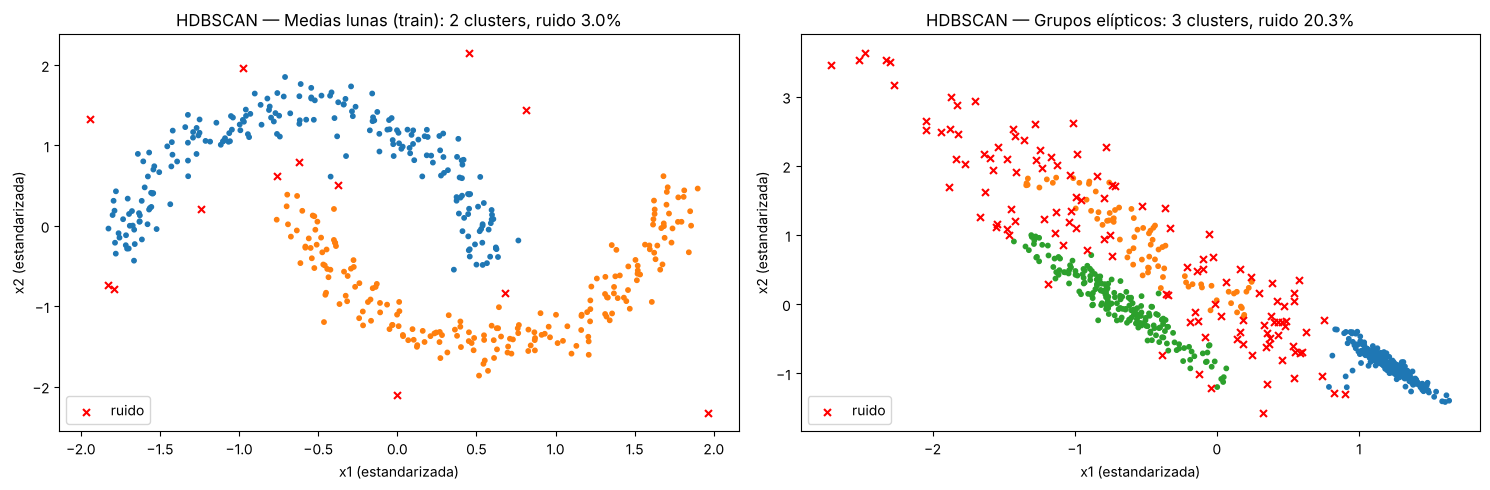

In [31]:
# Experimento 4: HDBSCAN en los dos escenarios (mismo min_samples = 5; grupo mínimo de 30 puntos = 5 % de 600)
from sklearn.cluster import HDBSCAN
def fila_hdb(nombre, Xs, y, h):
    l = h.labels_; m = l != -1
    return {'Escenario': nombre, 'clusters': len(set(l[m])), 'ruido %': round(100 * np.mean(~m), 1),
            'tamaños': sorted(np.bincount(l[m]).tolist(), reverse=True),
            'silueta (sin ruido)': round(silhouette_score(Xs[m], l[m]), 3),
            'ARI': round(adjusted_rand_score(y, l), 3), 'NMI': round(normalized_mutual_info_score(y, l), 3),
            'atípicos reales en el ruido': f"{int(((l == -1) & (y == -1)).sum())} de {int((y == -1).sum())}" if (y == -1).any() else '—',
            'falsas alarmas': int(((l == -1) & (y != -1)).sum()) if (y == -1).any() else '—'}
h_lunas = HDBSCAN(min_cluster_size=30, min_samples=5, copy=True).fit(Xs_tr)
h_elip = HDBSCAN(min_cluster_size=30, min_samples=5, copy=True).fit(Xb)
display(pd.DataFrame([fila_hdb('Medias lunas (entrenamiento)', Xs_tr, y_tr_ref, h_lunas),
                      fila_hdb('Grupos elípticos', Xb, yb, h_elip)]).set_index('Escenario'))
print('Grupos elípticos — HDBSCAN frente a la etiqueta real:')
print(pd.crosstab(yb, h_elip.labels_, rownames=['real'], colnames=['hdbscan']))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, Xs, h, tit in [(ax[0], Xs_tr, h_lunas, 'Medias lunas (train)'), (ax[1], Xb, h_elip, 'Grupos elípticos')]:
    l = h.labels_
    a.scatter(Xs[l != -1, 0], Xs[l != -1, 1], c=l[l != -1], cmap='tab10', vmin=0, vmax=9, s=10)
    a.scatter(Xs[l == -1, 0], Xs[l == -1, 1], c='red', marker='x', s=25, label='ruido')
    a.set_title(f'HDBSCAN — {tit}: {len(set(l[l != -1]))} clusters, ruido {np.mean(l == -1):.1%}')
    a.set_xlabel('x1 (estandarizada)'); a.set_ylabel('x2 (estandarizada)'); a.legend(loc='lower left')
plt.tight_layout(); plt.show()

### Experimento 4 — HDBSCAN

**Resultado.** HDBSCAN (Campello et al., 2013) construye la jerarquía de DBSCAN para **todos** los valores de eps y conserva los clusters más estables, así que se adapta a densidades variables. Se usaron min_samples = 5 y un grupo mínimo de 30 puntos.

- **Medias lunas (entrenamiento):** 2 clusters (216 y 205), 3 % de ruido y ARI 0,940, con 7 de los 12 atípicos en el ruido y 6 falsas alarmas. Es equivalente a DBSCAN, pero **sin tener que elegir eps**.
- **Grupos elípticos:** 3 clusters y ARI **0,769** (frente a 0,539 de DBSCAN). Separa el grupo medio del disperso, que es justo lo que DBSCAN no logró. Pero marca un **20,3 % como ruido**, casi todo del grupo disperso (108 de 200), y de ese grupo solo conserva 79 puntos como cluster.

**¿Resuelve el problema?** **Parcialmente.** Identifica tres grupos de densidades distintas, pero un grupo de baja densidad y mucha dispersión sigue viéndose, en buena parte, como ruido. Además, `HDBSCAN` de scikit-learn tampoco tiene `predict()`. En este escenario el GMM (0,956) sigue siendo superior, porque los datos son literalmente gaussianos.

### Conclusión: ¿cuándo funcionaría mejor el GMM y qué faltó?

Los dos escenarios muestran que **ningún modelo es mejor en abstracto**: gana el que tiene el supuesto que coincide con los datos. En las medias lunas, DBSCAN recuperó las dos estructuras curvas casi a la perfección (ARI 0,967) y detectó 5 de 8 atípicos sin falsas alarmas. El GMM con K = 2 cortó las lunas igual que K-Means (ARI 0,456), y el de menor BIC las partió en 8 elipses (ARI 0,287). En los grupos elípticos se invirtió el resultado: el GMM con K = 3 y covarianza full alcanzó un ARI de 0,956, mientras que ningún eps de DBSCAN logró separar los tres grupos (lo mejor sin etiquetas fue 0,539).

**El GMM es la mejor opción cuando:**

1. **Los grupos son aproximadamente elípticos**, aunque estén inclinados, tengan tamaños distintos o **se solapen**. El GMM asigna los puntos de la zona de solape por probabilidad, mientras que DBSCAN los fusiona.
2. **Los grupos tienen densidades distintas.** Cada componente tiene su propia covarianza, mientras que DBSCAN depende de un único eps.
3. **Se necesitan probabilidades:** revisar los casos dudosos, ponderar decisiones o medir el riesgo de error.
4. **Hay que asignar o puntuar datos nuevos con frecuencia:** `predict()` y `score_samples()` son nativos y el modelo se resume en pocos parámetros.

**Qué le faltó al GMM para separar las lunas:** un paso que **traduzca componentes en grupos**. Fusionar las 8 componentes por entropía elevó el ARI a 0,915 (0,933 con las anomalías), con apenas un punto incierto. Las alternativas probadas rindieron menos:

- **GMM bayesiano:** elige K solo, pero sigue usando 7 elipses (ARI 0,296).
- **Transformación con PCA de kernel:** inestable y sin forma de ajustarla sin etiquetas.

**Qué le faltó a DBSCAN en el escenario elíptico:** un umbral de densidad que se adapte a cada región. HDBSCAN lo aporta en parte: encontró 3 grupos (ARI 0,769), pero a costa de un 20 % de ruido.

**El riesgo de elegir K solo por BIC:** el BIC elige el mejor modelo de **densidad**, no la partición más **interpretable**. Aquí eligió 8 componentes para 2 lunas, y una de ellas era una elipse degenerada que convertía dos atípicos en los puntos «más normales» del dataset. Si el objetivo es encontrar grupos con sentido, el BIC debe complementarse con una regla de peso mínimo, la fusión de componentes y la revisión visual o de dominio.

**Qué cambiaría en la implementación para que el GMM rinda mejor:**

- **(a)** Fusionar componentes como parte del procedimiento estándar.
- **(b)** Poner un piso a las covarianzas (`reg_covar`) o un peso mínimo para evitar componentes degeneradas.
- **(c)** Fijar el umbral de anomalías con un criterio adaptativo (por ejemplo, un salto en la distribución de la log-densidad) en lugar de un percentil fijo.

El costo computacional no fue una limitación (milisegundos por modelo), pero en el GMM crece con K, con el número de reinicios y con la grilla de búsqueda.

# 8. Preguntas teóricas

**1. Explique la diferencia entre punto núcleo, frontera y ruido. ¿Qué pasa con cada tipo al aumentar min_samples?**

- **Núcleo:** tiene al menos `min_samples` puntos (contándose a sí mismo) a distancia ≤ eps. Es el único tipo que puede iniciar o expandir un cluster.
- **Frontera:** no alcanza ese mínimo, pero está a ≤ eps de algún núcleo, así que pertenece a su cluster sin expandirlo.
- **Ruido:** ni es núcleo ni está cerca de uno, y recibe la etiqueta −1 (Ester et al., 1996).

Al aumentar `min_samples` con eps fijo se exige más densidad para ser núcleo:

- **Los núcleos disminuyen:** de 414 a 376 al pasar de 5 a 10.
- **Los puntos frontera aumentan:** de 8 a 45, porque muchos antiguos núcleos siguen cerca de otro núcleo.
- **El ruido aumenta o se mantiene:** de 12 a 13, por los puntos frontera que se quedan sin ningún núcleo cerca.

Si se sube demasiado, los clusters se cortan en trozos o desaparecen.

**2. ¿Por qué el gráfico de k-distancias ayuda a elegir eps? ¿Qué representa el codo?**

La k-distancia de un punto es el **radio mínimo** que necesita para tener `min_samples` vecinos, es decir, para ser núcleo. Ordenada de menor a mayor, la curva tiene un tramo plano (puntos en zonas densas, con radios parecidos a la separación típica entre vecinos) y un tramo empinado (puntos aislados, que necesitan radios mucho mayores). El **codo** es la transición entre ambas poblaciones. Con eps cerca del codo, casi todos los puntos de las zonas densas son núcleo o frontera y los aislados quedan como ruido. Aquí el codo estuvo en 0,225 (percentil 94) y, con eps = 0,25, el ruido fue del 2,8 %.

**3. ¿Por qué las métricas internas deben calcularse sin el ruido en DBSCAN? ¿Qué pasaría si se incluyera como un cluster más?**

El ruido **no es un grupo**: son puntos dispersos por todo el plano, sin cohesión. Si se incluyera como un cluster más, su «centro» quedaría en medio de los datos y su dispersión interna sería enorme. Eso bajaría la silueta y subiría Davies-Bouldin aunque los clusters reales fueran perfectos. En esta guía, la silueta pasó de 0,391 a 0,312. Además, se penalizaría al modelo justo por detectar anomalías. Hay que reportar siempre el **% de ruido** junto a las métricas: excluirlo también permite «inflar» la silueta mandando a ruido los puntos difíciles.

**4. Describa los pasos E y M del algoritmo EM. ¿En qué se parece y en qué se diferencia de K-Means?**

- **Paso E:** con los parámetros actuales se calcula la responsabilidad $\gamma_{ik} = \pi_k \mathcal{N}(x_i \mid \mu_k, \Sigma_k) / \sum_j \pi_j \mathcal{N}(x_i \mid \mu_j, \Sigma_j)$, la probabilidad de que $x_i$ provenga de la componente k.
- **Paso M:** con $N_k = \sum_i \gamma_{ik}$ se actualizan $\pi_k = N_k / n$, $\mu_k = \sum_i \gamma_{ik} x_i / N_k$ y $\Sigma_k = \sum_i \gamma_{ik}(x_i - \mu_k)(x_i - \mu_k)^\top / N_k$.

Se repite hasta que la log-verosimilitud, que nunca disminuye, se estabiliza (Dempster et al., 1977; Bishop, 2006). Aquí convergió en 3 iteraciones con K = 2 y en 7 con K = 8.

- **Parecido con K-Means:** ambos alternan «asignar puntos» y «recalcular parámetros», dependen de la inicialización (por eso `n_init`) y requieren fijar K. K-Means es el caso límite de EM con covarianzas esféricas iguales $\sigma^2 I$ y $\sigma \to 0$.
- **Diferencias:**
  - EM asigna de forma **suave** (probabilidades) y K-Means de forma **dura**.
  - EM estima covarianzas (**elipses**) y pesos (**tamaños** distintos); K-Means solo centroides.
  - EM maximiza la **verosimilitud** y K-Means minimiza la **inercia**.
  - El GMM entrega una **densidad**, útil para detectar anomalías.

**5. ¿Qué penalizan BIC y AIC? ¿Por qué BIC tiende a elegir modelos más simples?**

Ambos penalizan el **número de parámetros** p, para que una mejor verosimilitud lograda solo agregando componentes no se confunda con un mejor modelo: $\text{AIC} = -2\ln \hat L + 2p$ y $\text{BIC} = -2\ln \hat L + p \ln n$. La penalización por parámetro del BIC, $\ln n$, supera a la del AIC (2) desde n ≥ 8. Con n = 434, cada parámetro cuesta ln(434) ≈ 6,07, tres veces más que en el AIC. Por eso el BIC elige modelos más simples. En esta guía, al ampliar hasta K = 15, el BIC se detuvo en K = 8, mientras que el AIC siguió bajando hasta K = 15 (Schwarz, 1978; Akaike, 1974).

**6. ¿Por qué los atípicos no fueron detectados con la regla IQR del EDA, pero sí con DBSCAN?**

La regla IQR es **univariada**: marca valores extremos de cada variable por separado. Los atípicos se generaron dentro del mismo rango que las lunas: x1 va de −1,19 a 2,41 y x2 de −0,94 a 1,38, dentro de los límites de la regla (−1,80 a 2,77 y −1,58 a 2,11). Lo atípico de ellos es la **combinación** de valores: caen en zonas vacías del plano, como el hueco entre las lunas. DBSCAN mira la **densidad en el espacio conjunto**: un punto así tiene menos de 5 vecinos a distancia ≤ eps y no está cerca de ningún núcleo, así que queda como ruido. No es infalible: 3 de los 8 atípicos de prueba cayeron a menos de eps de un núcleo y, por densidad, son indistinguibles de las lunas.

# Referencias

Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705

Baudry, J.-P., Raftery, A. E., Celeux, G., Lo, K., & Gottardo, R. (2010). Combining mixture components for clustering. *Journal of Computational and Graphical Statistics, 19*(2), 332–353. https://doi.org/10.1198/jcgs.2010.08111

Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.

Blei, D. M., & Jordan, M. I. (2006). Variational inference for Dirichlet process mixtures. *Bayesian Analysis, 1*(1), 121–143. https://doi.org/10.1214/06-BA104

Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27. https://doi.org/10.1080/03610927408827101

Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. En J. Pei, V. S. Tseng, L. Cao, H. Motoda y G. Xu (Eds.), *Advances in knowledge discovery and data mining* (pp. 160–172). Springer. https://doi.org/10.1007/978-3-642-37456-2_14

Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909

Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society: Series B (Methodological), 39*(1), 1–22. https://doi.org/10.1111/j.2517-6161.1977.tb01600.x

Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining* (pp. 226–231). AAAI Press.

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2.ª ed.). O'Reilly Media.

Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075

Murphy, K. P. (2012). *Machine learning: A probabilistic perspective*. MIT Press.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Satopää, V., Albrecht, J., Irwin, D., & Raghavan, B. (2011). Finding a "kneedle" in a haystack: Detecting knee points in system behavior. En *2011 31st International Conference on Distributed Computing Systems Workshops* (pp. 166–171). IEEE. https://doi.org/10.1109/ICDCSW.2011.20

Schölkopf, B., Smola, A., & Müller, K.-R. (1998). Nonlinear component analysis as a kernel eigenvalue problem. *Neural Computation, 10*(5), 1299–1319. https://doi.org/10.1162/089976698300017467

Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). DBSCAN revisited, revisited: Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems, 42*(3), Artículo 19. https://doi.org/10.1145/3068335

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136

Strehl, A., & Ghosh, J. (2002). Cluster ensembles: A knowledge reuse framework for combining multiple partitions. *Journal of Machine Learning Research, 3*, 583–617.